# CS-MON architecture: BIN62 Boondhi, from photograph to prediction

Run **Run All** in the existing **CS-MON GPU (WSL)** kernel, from the project root. This notebook is intentionally unexecuted. It uses the actual saved model in outputs/best_csmon.pt and displays all images, intermediate features and charts inline.

Only this notebook was created. Its code reads existing files and creates no exports, folders, downloads, installations, training runs or checkpoints. Save this same notebook after execution to keep its image outputs.

BIN62 is recorded as **Boondhi / High / training split**. Its label is a supplied visual intensity category. The filename, metadata and label are not model inputs. A prediction on this training image does not measure held-out performance or chemical concentration.

## 1. Complete architecture route

| Step | Operation | Output |
|---|---|---|
| Decode | JPEG → EXIF orientation → RGB | Whole photograph |
| Resize | Whole-image LANCZOS resize, divide by 255 | 1×3×224×224 |
| Colour encodings | RGB, HSV, CIELAB | Three 3-channel tensors |
| Projections | Three learned 1×1 convolutions + GELU | Three 12-channel maps |
| Gate context | Spatial averages, concatenate | 36 values |
| Colour gates | Linear 36→12, GELU, Linear 12→3, softmax | Three image-dependent weights |
| Fusion | Weighted sum | 12×224×224 |
| Adapter | 1×1 conv 12→3, 0.1 tanh, add original RGB | 3×224×224 |
| Normalize | ImageNet mean/std, once | 3×224×224 |
| Patch embedding v2 | 3×3 stride-2 conv 3→48, norm, GELU; 3×3 stride-2 conv 48→96, norm | 96×56×56 |
| Stage 1 | 2 VSS blocks, downsample v3 | 192×28×28 |
| Stage 2 | 2 VSS blocks, downsample v3 | 384×14×14 |
| Stage 3 | 8 VSS blocks, downsample v3 | 768×7×7 |
| Stage 4 | 2 VSS blocks, identity downsample | 768×7×7 |
| Pooling | Final norm, global average, flatten | 768 values |
| Ordinal head | Scalar score, two ordered cutpoints | Two cumulative logits |
| Decision | Sigmoid, cumulative-to-class conversion, argmax | Low / Medium / High |

Each VSS block: LayerNorm → SS2D → residual addition → LayerNorm → MLP → residual addition. SS2D mixes local neighbours and four directional selective scans. The checkpoint uses **v05_noz**: its optional internal z gate is disabled; the colour-fusion gate remains enabled.

Training augmentation consisted of horizontal/vertical flips. Inference here uses the original orientation. No segmentation, inferred ROI, denoising, histogram equalization or white balance is part of this implementation.

In [14]:
import sys
sys.dont_write_bytecode = True
import math, json, hashlib, types, functools
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.nn import functional as F
import kornia.color as colour

ROOT = Path.cwd().resolve()
assert (ROOT/'Dataset'/'BIN62.jpg').is_file(), 'Use the project root as working directory.'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
LABELS = ['Low','Medium','High']
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True})
print('Project:',ROOT,'\nDevice:',DEVICE)
print('Read-only inference; all figures remain inline.')

Project: /mnt/d/SLIIT (4th Year)/RP/food-colourant-detection 
Device: cuda
Read-only inference; all figures remain inline.


## 2. Verify BIN62 and display its metadata

The manifest supplies the identity, recorded label and split. Its SHA-256 must match the JPEG. Metadata are displayed for context only.

In [15]:
image_path=ROOT/'Dataset'/'BIN62.jpg'
manifest=pd.read_csv(ROOT/'outputs'/'split_manifest.csv').fillna('')
rows=manifest.loc[manifest.image_id.eq('BIN62')]
assert len(rows)==1
record=rows.iloc[0]
assert record.sweet=='Boondhi'
assert hashlib.sha256(image_path.read_bytes()).hexdigest()==record.sha256
display(record.to_frame('BIN62 metadata'))

,BIN62 metadata
relative_path,Dataset/BIN62.jpg
image_id,BIN62
sweet,Boondhi
colouring_intensity,High
label,2
split,train
audit_component,component_000058
sha256,e63b4c99e65c4a7c3252378ae8d1acabf38ff5c86e2966...
pixel_sha256,4813825fbfc7a489b7b507eea69b988f002e8af47ac6f6...
dhash,13146164642166213691


## 3. Decode, orient, convert to RGB and resize

Pillow decodes the JPEG, applies EXIF orientation, converts it to RGB and resizes the **whole image** to 224×224 with LANCZOS. A square resize may change the original aspect ratio; the background remains. Dividing byte values by 255 produces a float tensor in [0,1] with channels first and a batch dimension. If there is no EXIF rotation, the first two images will look identical.

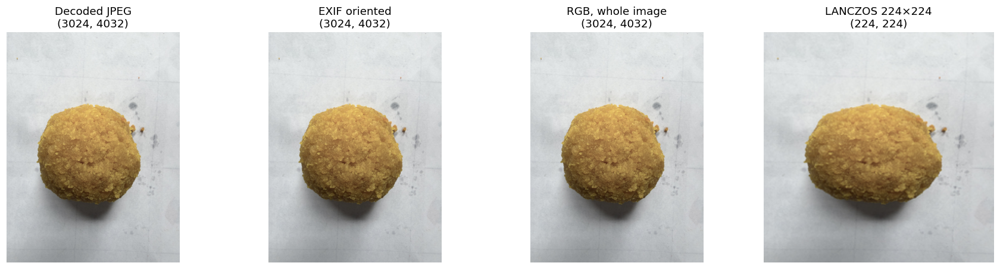

Model input: (1, 3, 224, 224) torch.float32 range: 0.0313725508749485 0.9607843160629272


In [16]:
with Image.open(image_path) as im:
    decoded=im.copy()
    oriented=ImageOps.exif_transpose(im).copy()
rgb_image=oriented.convert('RGB')
resized=rgb_image.resize((224,224),Image.Resampling.LANCZOS)
x=torch.from_numpy(np.array(resized,dtype=np.float32)/255).permute(2,0,1).unsqueeze(0).to(DEVICE)
fig,axes=plt.subplots(1,4,figsize=(16,4))
for ax,im,title in zip(axes,[decoded,oriented,rgb_image,resized],
    ['Decoded JPEG','EXIF oriented','RGB, whole image','LANCZOS 224×224']):
    ax.imshow(im); ax.set_title(f'{title}\n{im.size}'); ax.axis('off')
plt.show()
print('Model input:',tuple(x.shape),x.dtype,'range:',float(x.min()),float(x.max()))

## 4. Restore the exact trained model

The next cell embeds the model definitions from the existing training notebook. The loader verifies the **already cached pinned official VMamba source** against the checkpoint SHA-256, constructs the saved architecture and loads all saved parameters with strict=True. No pretrained download or randomly initialized prediction is used.

For this walkthrough the pinned implementation uses its **PyTorch reference selective-scan and cross-scan backends** to avoid Triton compilation/cache writes. It preserves the architecture and weights, but can be slower and produce small floating-point differences from accelerated inference. Use the existing WSL environment, where the source and dependencies are already installed.

In [17]:
class RGBNormalization(nn.Module):
    def __init__(self):
        super().__init__(); self.register_buffer('mean',torch.tensor([.485,.456,.406]).view(1,3,1,1))
        self.register_buffer('std',torch.tensor([.229,.224,.225]).view(1,3,1,1))
    def forward(self,x): return (x-self.mean)/self.std

def colour_representations(x):
    x=x.float()
    hsv=colour.rgb_to_hsv(x); hsv=torch.cat([hsv[:,:1]/(2*math.pi),hsv[:,1:]],dim=1)
    lab=colour.rgb_to_lab(x)
    lab=torch.cat([lab[:,:1]/50-1,lab[:,1:]/128],dim=1)
    return x*2-1,hsv*2-1,lab

class ColourFusion(nn.Module):
    def __init__(self,channels=12,gated=True):
        super().__init__(); self.gated=gated
        self.projections=nn.ModuleList([nn.Sequential(nn.Conv2d(3,channels,1),nn.GELU()) for _ in range(3)])
        self.gate=nn.Sequential(nn.Linear(3*channels,channels),nn.GELU(),nn.Linear(channels,3))
        self.adapter=nn.Conv2d(channels,3,1)
        nn.init.zeros_(self.adapter.weight); nn.init.zeros_(self.adapter.bias)
        self.last_gates=None
    def forward(self,x):
        assert x.ndim==4 and x.shape[1]==3
        with torch.autocast(device_type=x.device.type,enabled=False): reps=colour_representations(x)
        features=[projection(rep) for projection,rep in zip(self.projections,reps)]
        context=torch.cat([f.mean((2,3)) for f in features],dim=1)
        gates=self.gate(context).softmax(dim=1) if self.gated else context.new_full((x.shape[0],3),1/3)
        fused=sum(f*gates[:,i,None,None,None] for i,f in enumerate(features))
        self.last_gates=gates.detach()
        adapted=x+.1*torch.tanh(self.adapter(fused))
        assert adapted.shape==x.shape
        return adapted

class OrdinalHead(nn.Module):
    def __init__(self,features):
        super().__init__(); self.score=nn.Linear(features,1,bias=False)
        # Start with thresholds [-1, 1]. A gap <= log(4) makes Medium
        # unable to be the uniquely most probable class under argmax.
        # Both thresholds remain learnable; no predictions are forced.
        initial_gap=2.0
        self.first=nn.Parameter(torch.tensor(-initial_gap/2))
        self.raw_gap=nn.Parameter(torch.tensor(math.log(math.expm1(initial_gap-1e-4))))
    def forward(self,x):
        thresholds=torch.stack([self.first,self.first+F.softplus(self.raw_gap)+1e-4])
        return self.score(x)-thresholds

def ordinal_targets(y): return (y[:,None]>torch.arange(2,device=y.device)[None,:]).float()
def ordinal_loss(logits,y): return F.binary_cross_entropy_with_logits(logits,ordinal_targets(y))
def class_probabilities(logits,ordinal=True):
    if not ordinal: return logits.float().softmax(1)
    cumulative=logits.float().sigmoid()
    return torch.stack([1-cumulative[:,0],cumulative[:,0]-cumulative[:,1],cumulative[:,1]],dim=1)

class ResearchModel(nn.Module):
    def __init__(self,backbone,features,fusion=None,ordinal=True,is_vmamba=False):
        super().__init__(); self.backbone=backbone; self.fusion=fusion
        self.normalization=RGBNormalization(); self.ordinal=ordinal; self.is_vmamba=is_vmamba
        self.head=OrdinalHead(features) if ordinal else nn.Linear(features,3)
        self.frozen_backbone=False; self.frozen_modules=[]
    def features(self,x):
        if self.fusion is not None: x=self.fusion(x)
        return self.backbone(self.normalization(x))
    def forward(self,x): return self.head(self.features(x))
    def train(self,mode=True):
        super().train(mode)
        if mode:
            if self.frozen_backbone: self.backbone.eval()
            for module in self.frozen_modules: module.eval()
        return self

In [18]:
payload=torch.load(ROOT/'outputs'/'best_csmon.pt',map_location='cpu',weights_only=False)
assert payload['class_mapping']=={'Low':0,'Medium':1,'High':2}
arch=payload['architecture']; prep=payload['preprocessing']
assert arch['spec']['kind']=='vmamba' and arch['spec']['fusion']=='gated' and arch['spec']['ordinal']
assert arch['fusion_channels']==12 and prep['image_size']==224
assert arch['vmamba_kwargs']['forward_type']=='v05_noz'
provenance=payload['vmamba_provenance']
source_path=Path.home()/'.cache'/'csmon'/f"vmamba-{provenance['commit']}.py"
assert source_path.is_file(), f'Use the existing WSL kernel; cached source missing: {source_path}'
source_bytes=source_path.read_bytes()
assert hashlib.sha256(source_bytes).hexdigest()==provenance['source_sha256']
vmamba=types.ModuleType('bin62_readonly_vmamba')
vmamba.__file__=str(source_path)
sys.modules[vmamba.__name__]=vmamba
exec(compile(source_bytes,str(source_path),'exec'),vmamba.__dict__)
backbone=vmamba.VSSM(**arch['vmamba_kwargs'])
backbone.classifier.head=nn.Identity()
model=ResearchModel(backbone,768,ColourFusion(channels=12,gated=True),True,is_vmamba=True)
model.load_state_dict(payload['state_dict'],strict=True)
model.to(DEVICE).eval()
for module in model.backbone.modules():
    if isinstance(module,vmamba.SS2D):
        module.forward_core=functools.partial(module.forward_corev2,
            force_fp32=False,no_einsum=True,selective_scan_backend='torch',scan_force_torch=True)
assert not model.training
print('Strict state loading passed. Selected epoch:',payload['selected_epoch'])
display(pd.Series({'commit':provenance['commit'],'source_sha256':provenance['source_sha256'],
    'parameters':sum(p.numel() for p in model.parameters()),'scan_backend':'PyTorch reference'}))
print(model)

Strict state loading passed. Selected epoch: 20


commit                    2ed52ead062a51a64521ed3871d52914bf532876
source_sha256    572207a2b6553ff85d81b602eebda2041623073f01fc0c...
parameters                                                29481500
scan_backend                                     PyTorch reference
dtype: object

ResearchModel(
  (backbone): VSSM(
    (patch_embed): Sequential(
      (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): Identity()
      (2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
      (3): Identity()
      (4): GELU(approximate='none')
      (5): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (6): Identity()
      (7): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
    )
    (layers): ModuleList(
      (0): Sequential(
        (blocks): Sequential(
          (0): VSSBlock(
            (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
            (op): SS2D(
              (out_norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
              (in_proj): Linear(in_features=96, out_features=96, bias=False)
              (act): SiLU()
              (conv2d): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=96, bias=False)
              (x_proj): Linear(in_features=96, 

## 5. How to read intermediate images

Only genuine RGB tensors are shown as photographs. Colour channels and learned features are shown as scalar heatmaps with numeric colour scales. Feature panels show the channel mean and first three channels. Sequence tensors are shown as channel-versus-position heatmaps. Plot scales do not modify the tensor used by the model; feature brightness is not a causal attribution or a segmentation mask.

In [19]:
def rgb_array(t):
    return t.detach().float().cpu()[0].permute(1,2,0).numpy()

def channel_grid(t,names,title,limits=None):
    a=t.detach().float().cpu()[0].numpy()
    fig,axes=plt.subplots(1,len(names),figsize=(4*len(names),3.4),squeeze=False)
    for i,(ax,name) in enumerate(zip(axes[0],names)):
        options={} if limits is None else dict(vmin=limits[i][0],vmax=limits[i][1])
        p=ax.imshow(a[i],cmap='twilight' if name=='Hue' else 'viridis',**options)
        ax.set_title(name); ax.axis('off'); fig.colorbar(p,ax=ax,shrink=.7)
    fig.suptitle(title); plt.show()

def feature_panel(t,title):
    a=t.detach().float().cpu()
    if a.ndim==4:
        a=a[0]; maps=[a.mean(0),*a[:min(3,a.shape[0])]]
        names=['Channel mean',*[f'Channel {i}' for i in range(len(maps)-1)]]
        fig,axes=plt.subplots(1,len(maps),figsize=(3.5*len(maps),3),squeeze=False)
        for ax,m,name in zip(axes[0],maps,names):
            p=ax.imshow(m.numpy(),cmap='viridis'); ax.set_title(name); ax.axis('off')
            fig.colorbar(p,ax=ax,shrink=.65)
    else:
        fig,ax=plt.subplots(figsize=(12,2.8))
        m=a[0] if a.ndim>1 else a
        m=m.reshape(-1,m.shape[-1]) if m.ndim>1 else m[None,:]
        p=ax.imshow(m.numpy(),aspect='auto',cmap='coolwarm'); fig.colorbar(p,ax=ax)
        ax.set(xlabel='Position / feature index',ylabel='Channel / row')
    fig.suptitle(f'{title} | shape {tuple(t.shape)}'); plt.show()

## 6. RGB, HSV and CIELAB: three views of BIN62

RGB preserves red/green/blue. HSV separates hue, saturation and value. CIELAB separates perceptual lightness from green–red and blue–yellow axes. They describe the **same pixels**, not independent photographs.

Kornia hue is divided by 2π to express one turn as [0,1]. The learned projection inputs are RGB and HSV scaled by 2v−1, and Lab scaled as (L*/50−1, a*/128, b*/128). Hue is circular and unstable at low saturation. HSV/Lab arrays are never displayed as RGB.

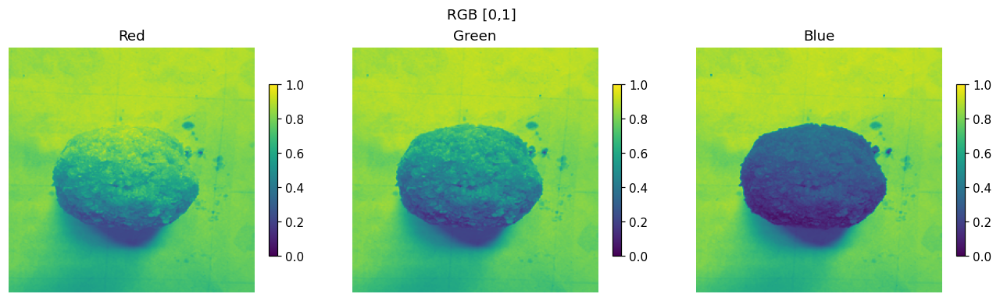

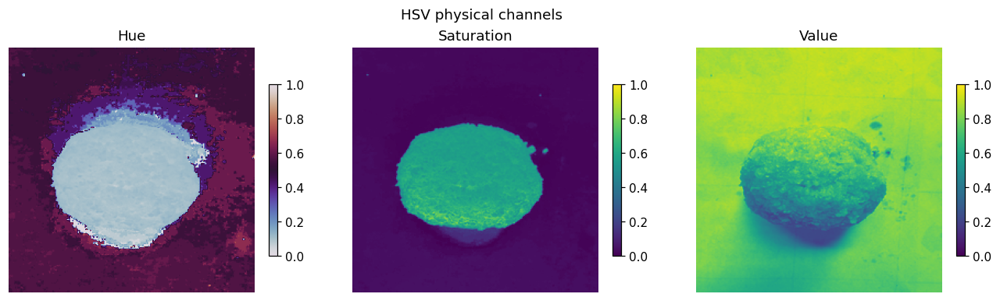

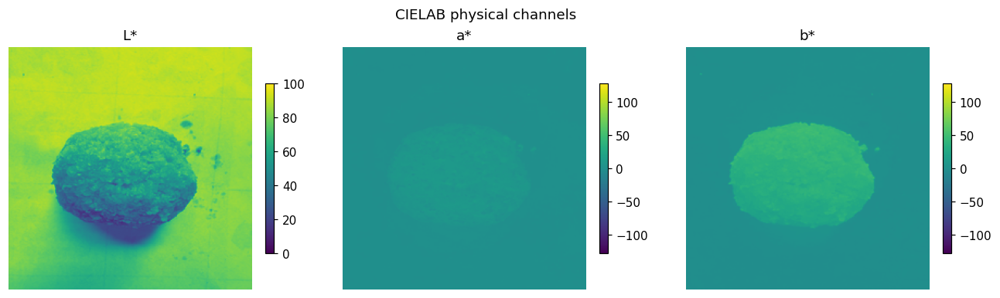

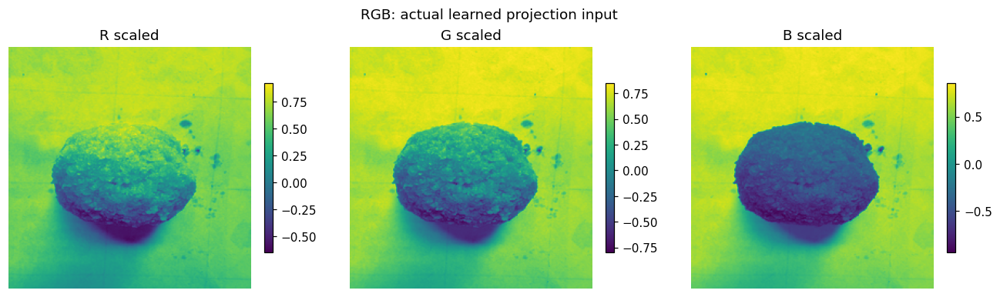

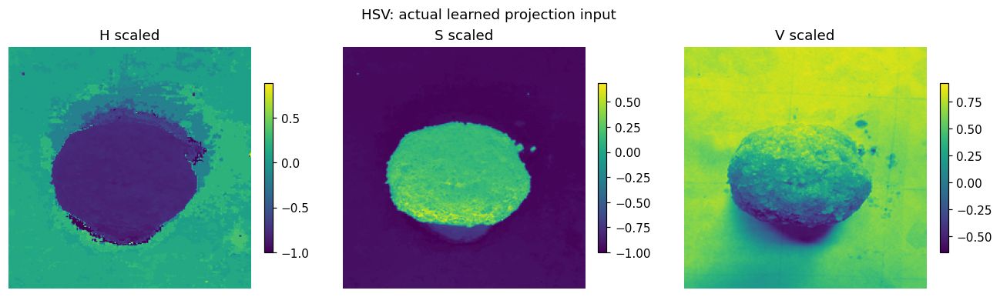

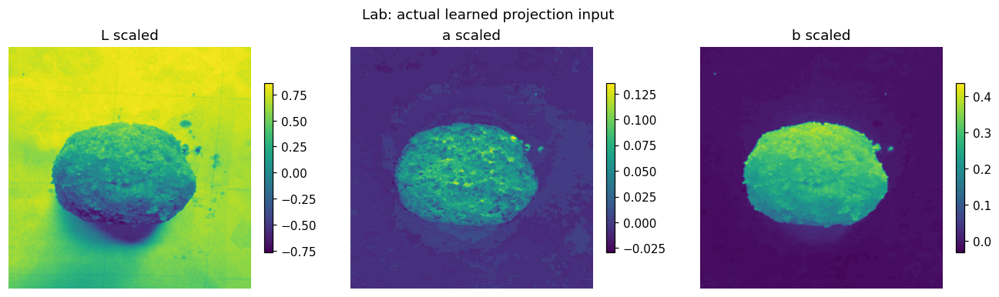

In [20]:
with torch.no_grad():
    reps=colour_representations(x)
    hsv=colour.rgb_to_hsv(x)
    hsv=torch.cat([hsv[:,:1]/(2*math.pi),hsv[:,1:]],1)
    lab=colour.rgb_to_lab(x)
channel_grid(x,['Red','Green','Blue'],'RGB [0,1]',[(0,1)]*3)
channel_grid(hsv,['Hue','Saturation','Value'],'HSV physical channels',[(0,1)]*3)
channel_grid(lab,['L*','a*','b*'],'CIELAB physical channels',[(0,100),(-128,128),(-128,128)])
for rep,names,name in zip(reps,
    [['R scaled','G scaled','B scaled'],['H scaled','S scaled','V scaled'],['L scaled','a scaled','b scaled']],
    ['RGB','HSV','Lab']):
    channel_grid(rep,names,f'{name}: actual learned projection input')

## 7. Learned colour projections and image-dependent gates

Each branch applies a learned 1×1 convolution from 3 to 12 channels, then GELU. This mixes the three colour components at each position without mixing neighbouring pixels. Spatial averaging produces 12 values per branch, concatenated into 36.

The gate network applies Linear(36,12) → GELU → Linear(12,3) → softmax. Its three weights sum to one and control the colour branches for this image. They are global branch weights, not pixel attention or class probabilities.

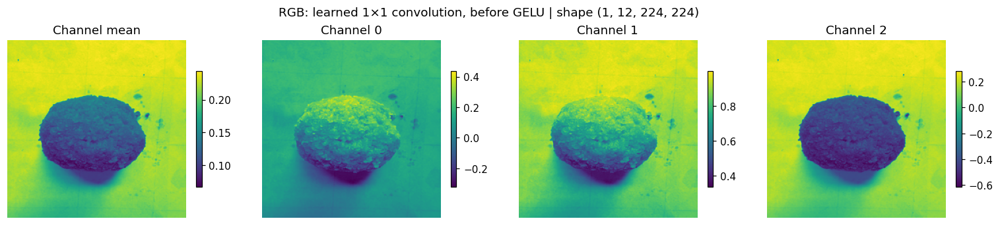

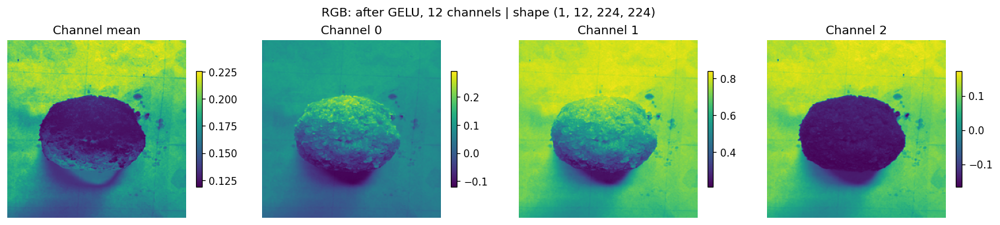

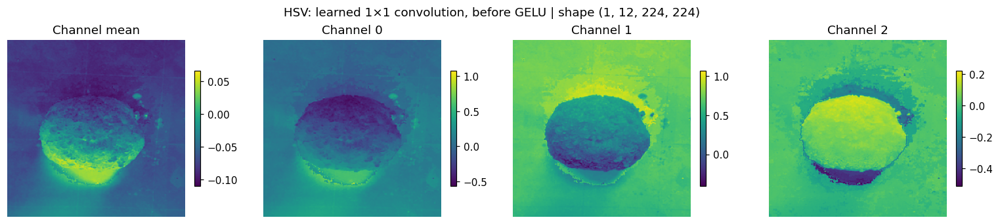

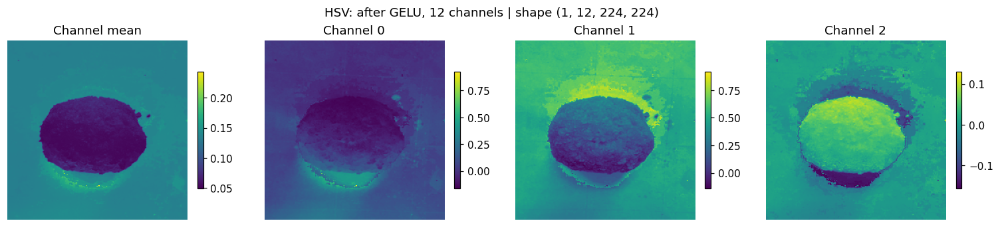

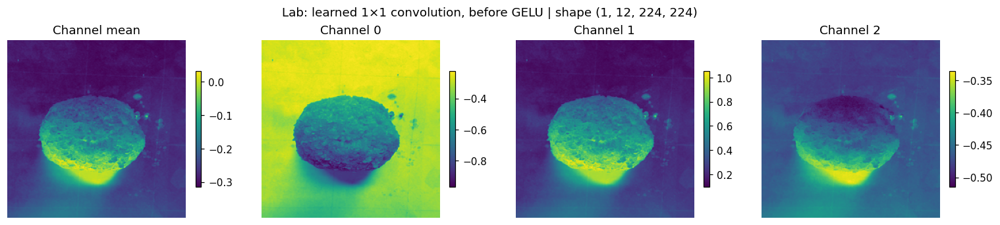

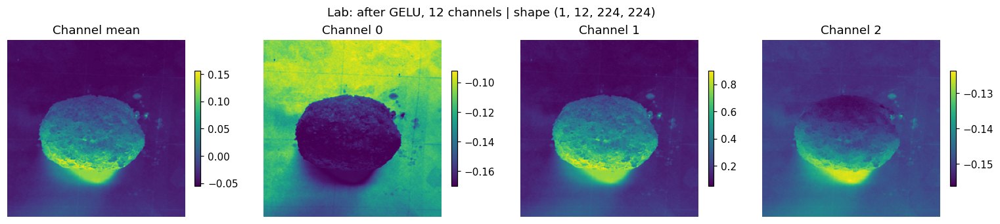

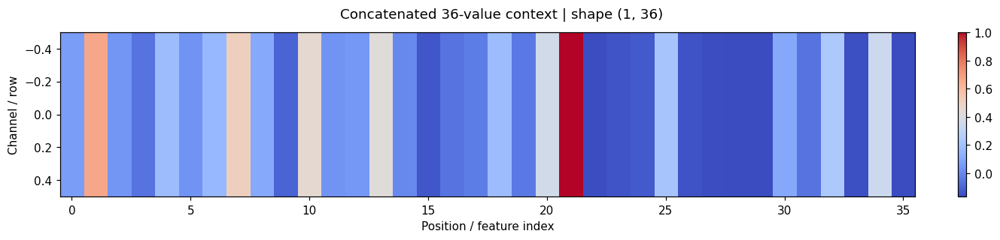

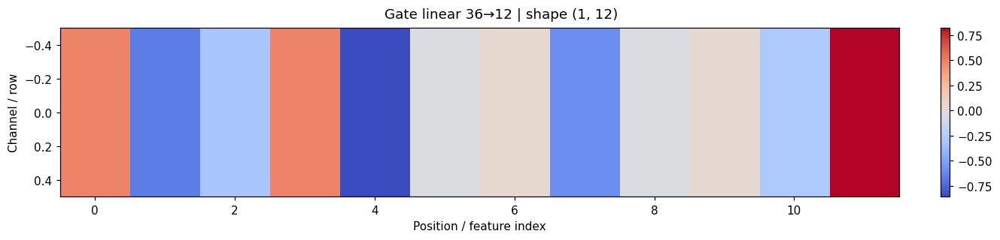

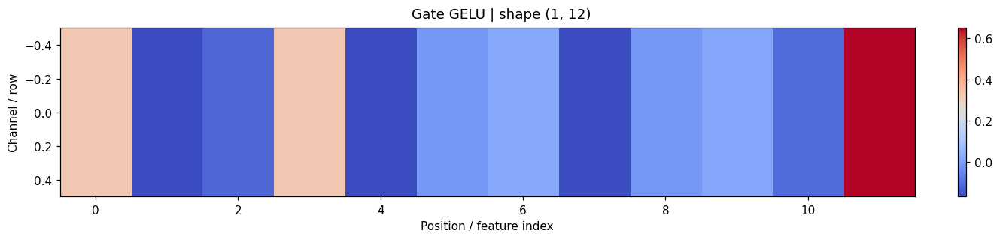

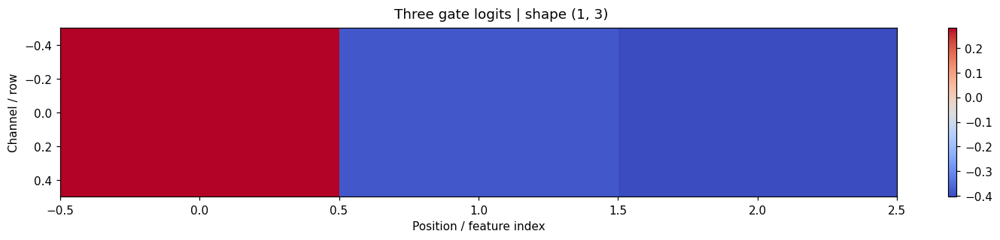

,Colour space,Gate logit,Weight
0,RGB,0.281026,0.495447
1,HSV,-0.384469,0.254669
2,Lab,-0.403438,0.249884


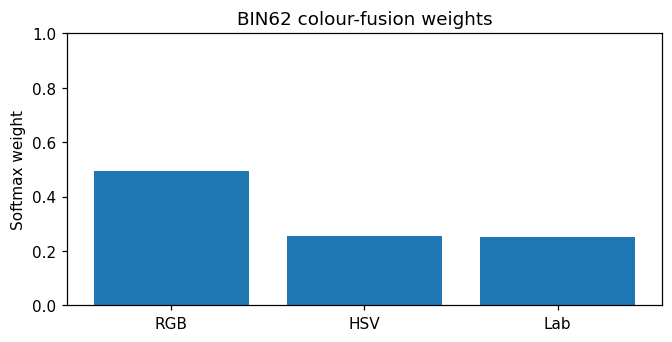

In [21]:
with torch.no_grad():
    projection_linear=[branch[0](rep) for branch,rep in zip(model.fusion.projections,reps)]
    projected=[branch[1](z) for branch,z in zip(model.fusion.projections,projection_linear)]
    context=torch.cat([f.mean((2,3)) for f in projected],1)
    gate_hidden=model.fusion.gate[0](context)
    gate_activated=model.fusion.gate[1](gate_hidden)
    gate_logits=model.fusion.gate[2](gate_activated)
    gates=gate_logits.softmax(1)
for name,z,f in zip(['RGB','HSV','Lab'],projection_linear,projected):
    feature_panel(z,f'{name}: learned 1×1 convolution, before GELU')
    feature_panel(f,f'{name}: after GELU, 12 channels')
for title,t in [('Concatenated 36-value context',context),('Gate linear 36→12',gate_hidden),
    ('Gate GELU',gate_activated),('Three gate logits',gate_logits)]:
    feature_panel(t,title)
display(pd.DataFrame({'Colour space':['RGB','HSV','Lab'],
    'Gate logit':gate_logits[0].cpu().numpy(),'Weight':gates[0].cpu().numpy()}))
fig,ax=plt.subplots(figsize=(6,3)); ax.bar(['RGB','HSV','Lab'],gates[0].cpu().numpy())
ax.set(title='BIN62 colour-fusion weights',ylabel='Softmax weight',ylim=(0,1)); plt.show()

## 8. Weighted fusion and residual RGB adapter

The weighted sum F = g_RGB F_RGB + g_HSV F_HSV + g_Lab F_Lab has 12 channels. A learned 1×1 convolution reduces it to three channels. The model then uses **adapted = original + 0.1 tanh(adapter(F))**.

The correction is bounded to approximately ±0.1 per channel. Adapted RGB itself is not clamped and may slightly exceed [0,1]. Only the photograph preview is clipped for display; the model receives the actual tensor. The signed difference heatmaps show exactly what the learned adapter changes. The adapter was zero-initialized during training; these are its saved trained weights.

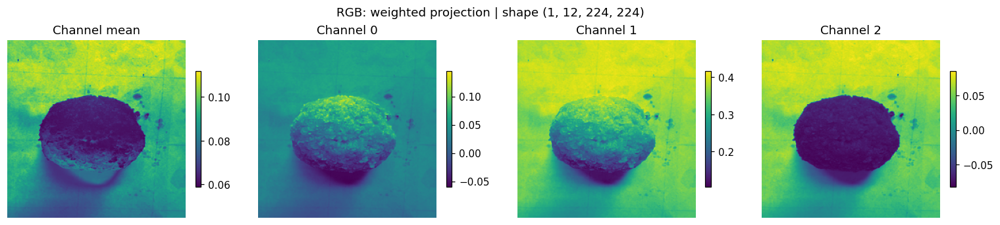

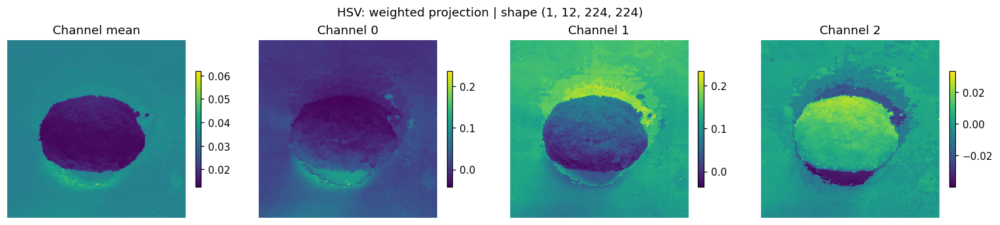

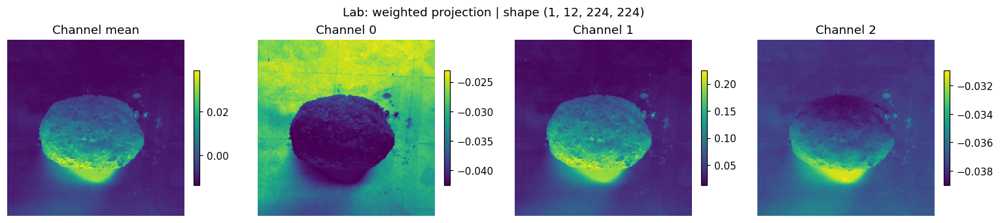

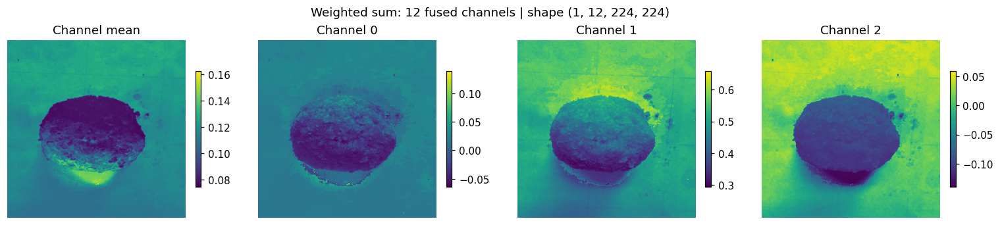

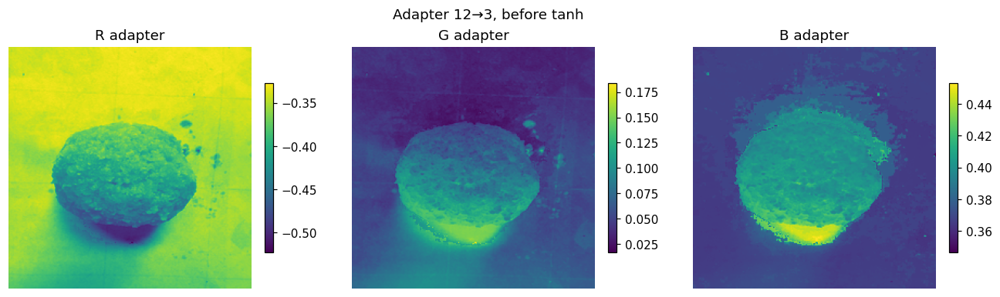

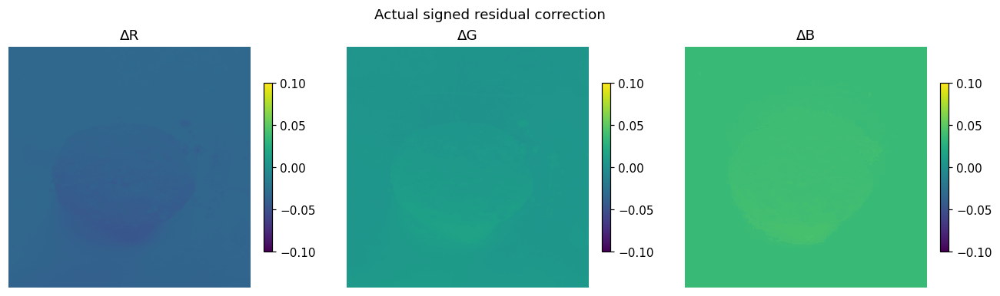

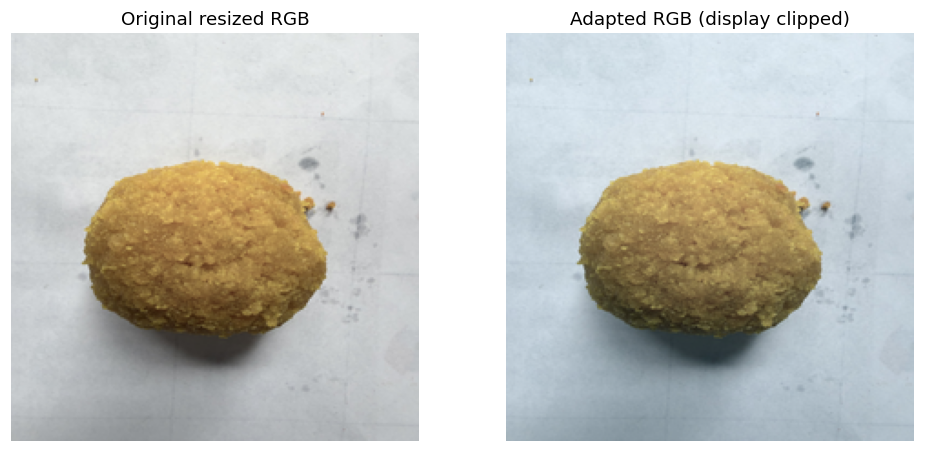

Actual adapted range: 0.0711599737405777 0.9646413922309875


In [22]:
with torch.no_grad():
    weighted=[f*gates[:,i,None,None,None] for i,f in enumerate(projected)]
    fused=sum(weighted)
    adapter_raw=model.fusion.adapter(fused)
    correction=.1*torch.tanh(adapter_raw)
    adapted=x+correction
    torch.testing.assert_close(adapted,model.fusion(x))
for name,w in zip(['RGB','HSV','Lab'],weighted):
    feature_panel(w,f'{name}: weighted projection')
feature_panel(fused,'Weighted sum: 12 fused channels')
channel_grid(adapter_raw,['R adapter','G adapter','B adapter'],'Adapter 12→3, before tanh')
channel_grid(correction,['ΔR','ΔG','ΔB'],'Actual signed residual correction',[(-.1,.1)]*3)
fig,axes=plt.subplots(1,2,figsize=(9,4))
axes[0].imshow(rgb_array(x)); axes[0].set_title('Original resized RGB')
axes[1].imshow(np.clip(rgb_array(adapted),0,1)); axes[1].set_title('Adapted RGB (display clipped)')
for ax in axes: ax.axis('off')
plt.show()
print('Actual adapted range:',float(adapted.min()),float(adapted.max()))

## 9. ImageNet normalization

The adapted RGB is normalized **once** before the backbone: (v−mean)/std, using mean [0.485,0.456,0.406] and std [0.229,0.224,0.225]. Negative values are expected. The panels show scalar normalized channels rather than clipped RGB.

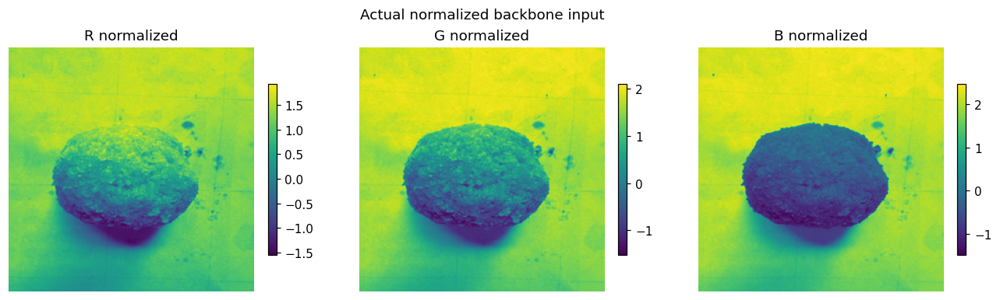

In [23]:
with torch.no_grad(): normalized=model.normalization(adapted)
channel_grid(normalized,['R normalized','G normalized','B normalized'],'Actual normalized backbone input')

## 10. Capture every executed backbone module

Temporary hooks record every module output, its actual shape and value range. Spatial previews are channel means; sequence previews keep channel versus position. The source's built-in SS2D debug interface exposes the actual directional input/output sequences, selective parameters and merged responses for all 14 blocks.

One inference pass collects the results. Hooks and debug attributes are removed afterwards. Containers and identity modules repeat some results. These visuals do not alter the model weights or input.

In [24]:
trace={}; trace_rows=[]; handles=[]; scan_data={}
def recorder(name):
    def hook(module,inputs,output):
        if not isinstance(output,torch.Tensor): return
        t=output.detach().float()
        trace_rows.append({'Module':name,'Shape':str(tuple(t.shape)),
            'Min':float(t.min()),'Max':float(t.max()),'Mean':float(t.mean())})
        if t.ndim==4: trace[name]=t[0].mean(0).detach().cpu().numpy()
        elif t.ndim==3: trace[name]=t[0].detach().cpu().numpy()
        else: trace[name]=t.reshape(1,-1).detach().cpu().numpy()
    return hook
ops=[]
for name,module in model.backbone.named_modules():
    if name: handles.append(module.register_forward_hook(recorder(name)))
    if isinstance(module,vmamba.SS2D):
        module.__DEBUG__=True
        ops.append((name,module))
try:
    with torch.no_grad():
        embedding=model.backbone(normalized)
        logits=model.head(embedding)
        probabilities=class_probabilities(logits)
    # Debug data includes trainable parameters (delta_bias); detach all visualization arrays.
    for name,op in ops:
        data=getattr(op,'__data__')
        H,W=data['H'],data['W']; D=op.d_inner
        scan_data[name]={'H':H,'W':W,
            'inputs':data['us'][0].reshape(4,D,H*W).mean(1).detach().cpu().numpy(),
            'outputs':data['ys'][0].reshape(4,D,H*W).mean(1).detach().cpu().numpy(),
            'merged':data['y'][0].reshape(D,H,W).mean(0).detach().cpu().numpy(),
            'delta':F.softplus(data['dts'][0]+data['delta_bias'][:,None]).reshape(4,D,H*W).mean(1).detach().cpu().numpy(),
            'B':data['Bs'][0].mean(1).detach().cpu().numpy(),
            'C':data['Cs'][0].mean(1).detach().cpu().numpy()}
finally:
    for h in handles: h.remove()
    for name,op in ops:
        if hasattr(op,'__data__'): delattr(op,'__data__')
        if hasattr(op,'__DEBUG__'): delattr(op,'__DEBUG__')
trace_table=pd.DataFrame(trace_rows)
with pd.option_context('display.max_rows',None,'display.max_colwidth',100):
    display(trace_table)
print('Captured',len(scan_data),'selective-scan blocks; hooks removed.')
assert len(scan_data)==sum(arch['vmamba_kwargs']['depths'])==14
assert embedding.shape==(1,768) and logits.shape==(1,2)

,Module,Shape,Min,Max,Mean
0,patch_embed.0,"(1, 48, 112, 112)",-0.928071,0.947283,0.007233
1,patch_embed.1,"(1, 48, 112, 112)",-0.928071,0.947283,0.007233
2,patch_embed.2,"(1, 48, 112, 112)",-7.130592,8.086468,0.180390
3,patch_embed.3,"(1, 48, 112, 112)",-7.130592,8.086468,0.180390
4,patch_embed.4,"(1, 48, 112, 112)",-0.169971,8.086468,0.229164
5,patch_embed.5,"(1, 96, 56, 56)",-20.219250,5.763904,-0.102172
6,patch_embed.6,"(1, 96, 56, 56)",-20.219250,5.763904,-0.102172
7,patch_embed.7,"(1, 96, 56, 56)",-2.259665,2.538059,0.002370
8,patch_embed,"(1, 96, 56, 56)",-2.259665,2.538059,0.002370
9,layers.0.blocks.0.norm,"(1, 96, 56, 56)",-19.949261,25.639727,0.072585


Captured 14 selective-scan blocks; hooks removed.


## 11. Patch embedding, operation by operation

Version v2 applies a 3×3 stride-2 convolution 3→48 at 112×112, LayerNorm, GELU, then a 3×3 stride-2 convolution 48→96 at 56×56 and LayerNorm. The resulting grid contains 3,136 spatial tokens. A token is a learned feature vector with an overlapping receptive field, not a literal 4×4 RGB patch.

Every executed patch-embedding module is shown below; identity operations repeat the preceding map.

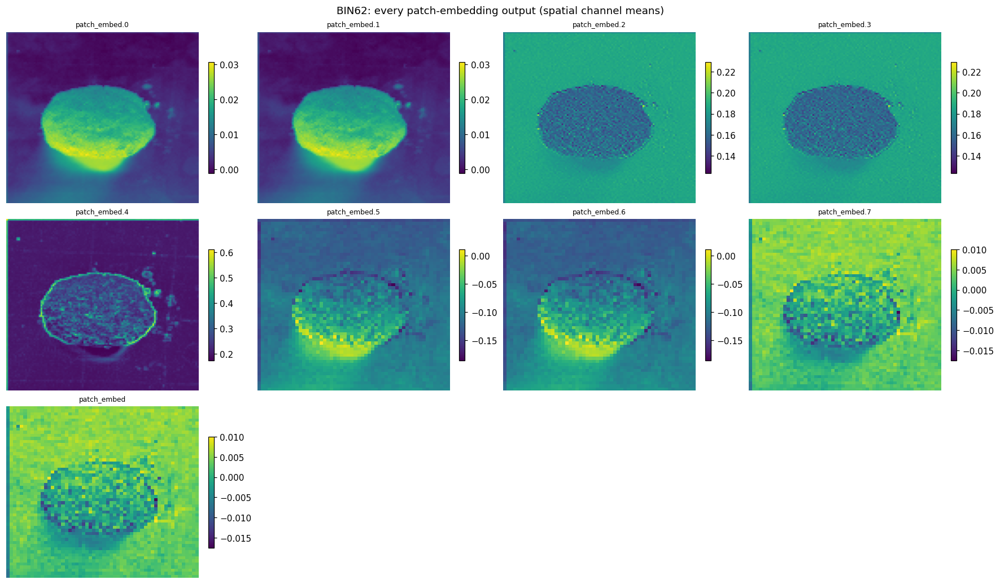

In [25]:
def trace_gallery(items,title,cols=4):
    if not items: return
    rows=math.ceil(len(items)/cols)
    fig,axes=plt.subplots(rows,cols,figsize=(4*cols,3.1*rows),squeeze=False)
    for ax,(name,array) in zip(axes.flat,items):
        p=ax.imshow(array,cmap='viridis',aspect='auto')
        ax.set_title(name,fontsize=8); ax.axis('off')
        fig.colorbar(p,ax=ax,shrink=.65)
    for ax in list(axes.flat)[len(items):]: ax.axis('off')
    fig.suptitle(title); plt.show()
trace_gallery([(k,v) for k,v in trace.items() if k.startswith('patch_embed')],
    'BIN62: every patch-embedding output (spatial channel means)')

## 12. Inside SS2D: four traversals and selective memory

Each SS2D path applies an input projection, 3×3 depthwise convolution and SiLU before scanning. Depthwise convolution mixes nearby positions separately per channel. Cross-scan creates four flattened traversals: **row-major forward, column-major forward, row-major reverse, column-major reverse**. These are complete grid traversals, not four isolated straight lines through the food.

Learned projections generate position-dependent Δ, B and C. A = −exp(A_logs) controls state dynamics and D is a learned skip coefficient. Conceptually the selective recurrence is:

- h_t = exp(Δ_t A) h_(t−1) + Δ_t B_t u_t
- y_t = C_t h_t + D u_t

The implementation applies softplus to Δ plus its learned bias. State dimension is 1 per channel and direction in this checkpoint. The sequence memory carries context across the traversal. The learned A and D values are also displayed below.

Cross-merge reverses the backward sequences, restores column-major sequences to image coordinates and **sums** all four aligned responses. Output normalization and projection return to the block channel width. v05_noz disables the optional internal z gate.

For each of all 14 blocks, the following cell shows actual scan inputs, positive Δ, B, C, scan outputs, aligned directional responses and merged response. Sequence images use scan position on the horizontal axis; spatial images put the results back at their grid locations. These are feature responses, not attention or attribution maps.

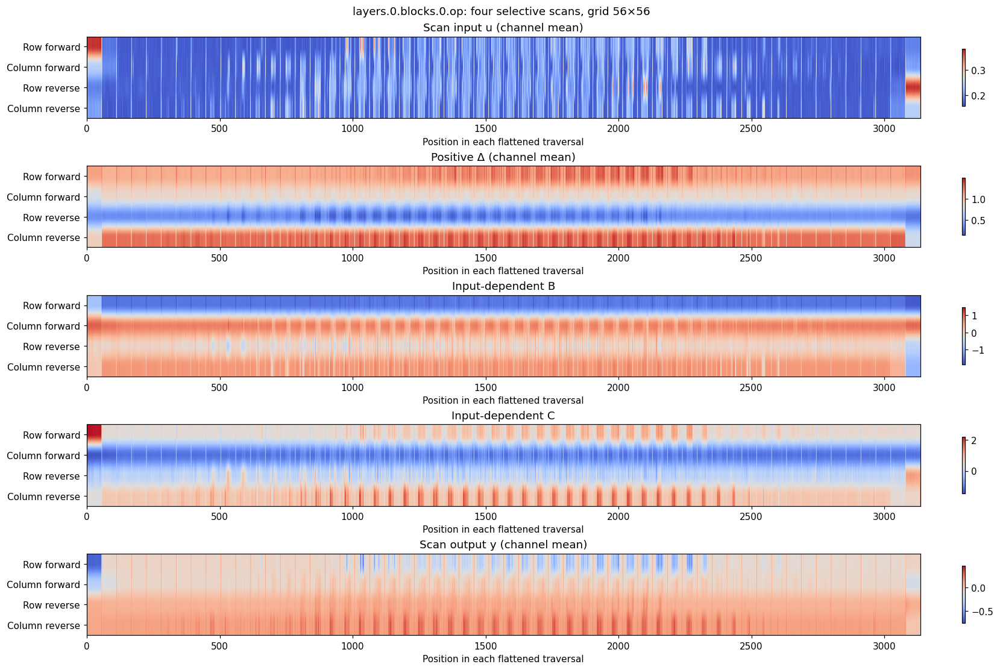

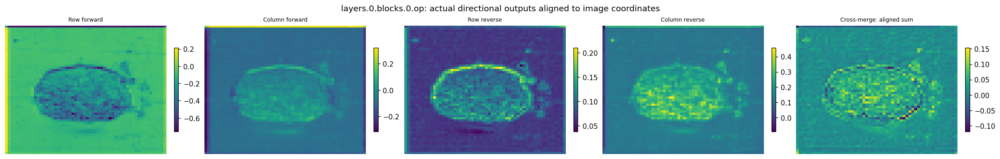

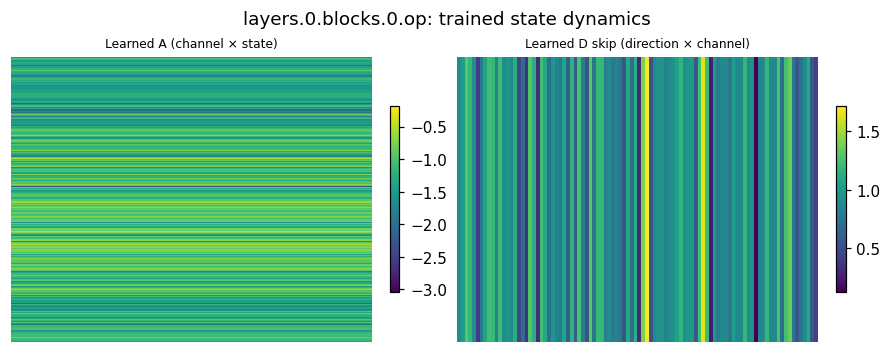

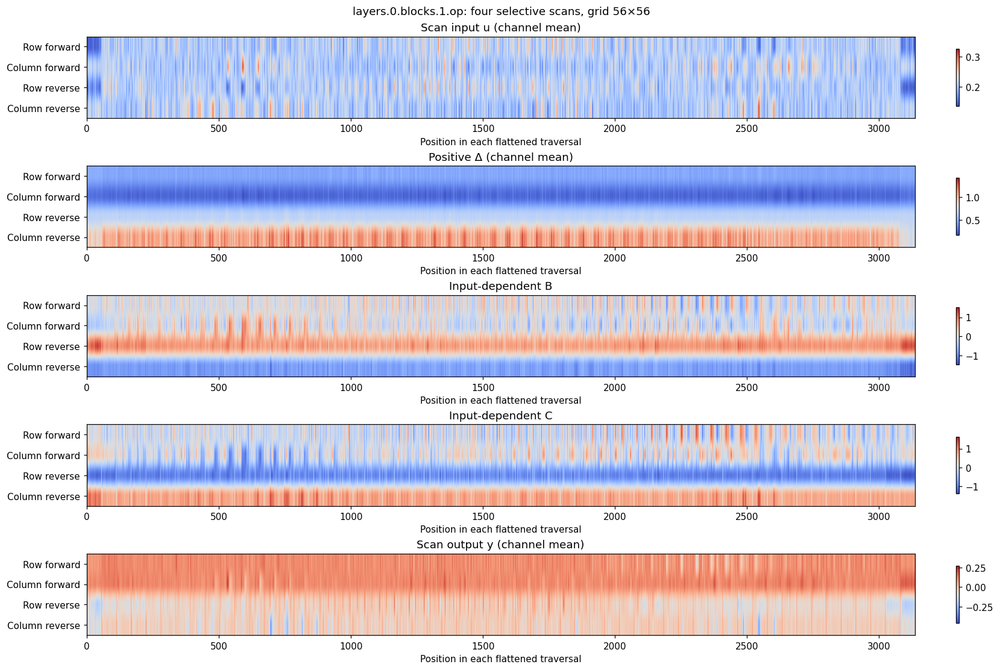

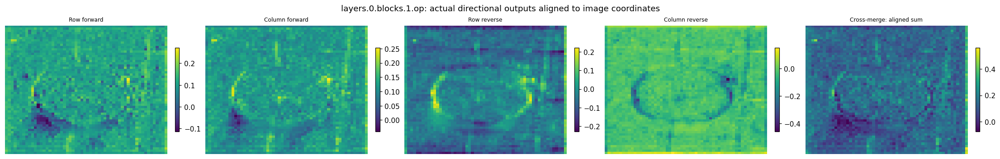

...

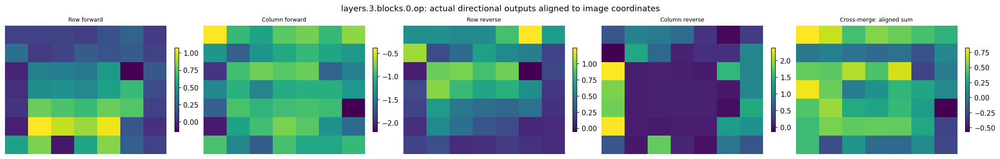

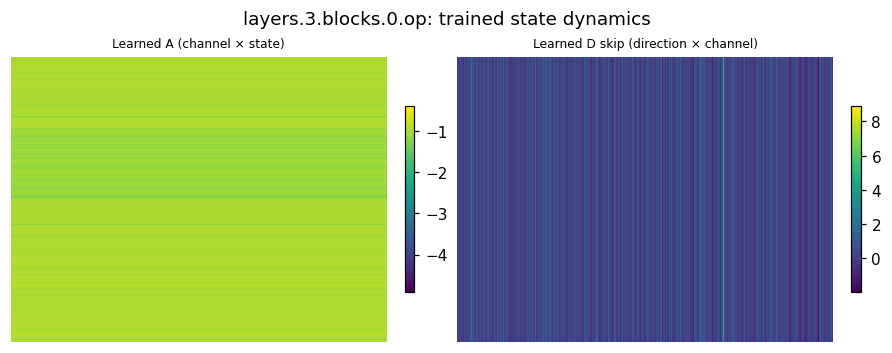

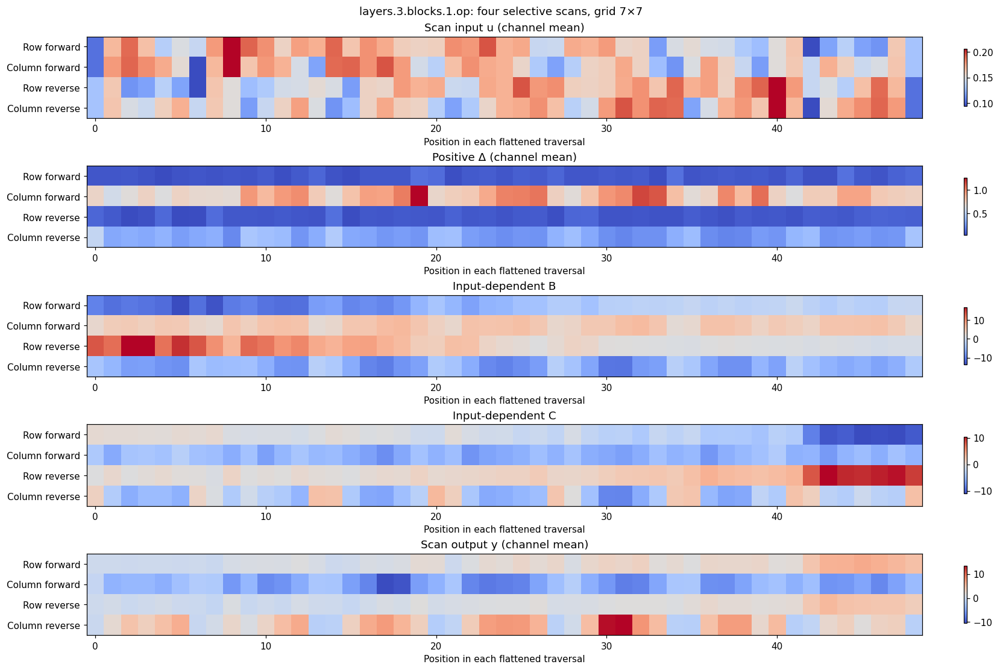

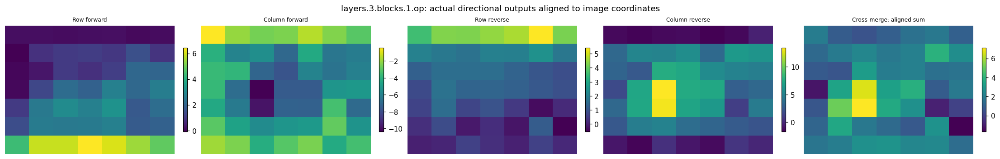

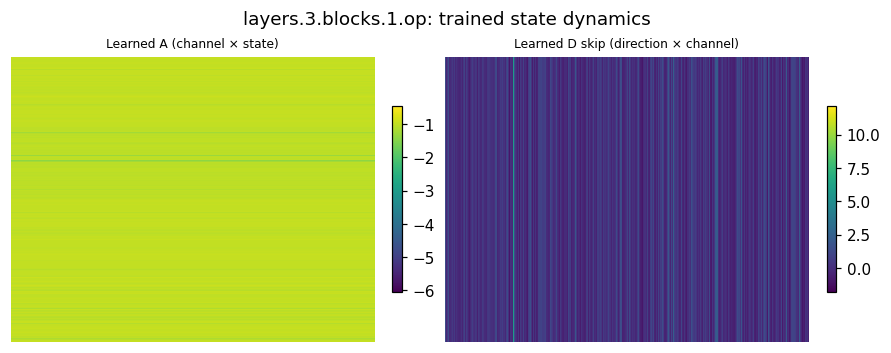

In [26]:
directions=['Row forward','Column forward','Row reverse','Column reverse']
for name,data in scan_data.items():
    H,W=data['H'],data['W']
    fig,axes=plt.subplots(5,1,figsize=(15,10))
    for ax,key,label in zip(axes,['inputs','delta','B','C','outputs'],
        ['Scan input u (channel mean)','Positive Δ (channel mean)',
         'Input-dependent B','Input-dependent C','Scan output y (channel mean)']):
        p=ax.imshow(data[key],aspect='auto',cmap='coolwarm')
        ax.set_yticks(range(4),directions); ax.set_title(label)
        ax.set_xlabel('Position in each flattened traversal')
        fig.colorbar(p,ax=ax,shrink=.7)
    fig.suptitle(f'{name}: four selective scans, grid {H}×{W}'); plt.show()
    seq=data['outputs']
    aligned=[seq[0].reshape(H,W),seq[1].reshape(W,H).T,
        seq[2,::-1].reshape(H,W),seq[3,::-1].reshape(W,H).T]
    trace_gallery(list(zip(directions,aligned))+[('Cross-merge: aligned sum',data['merged'])],
        name+': actual directional outputs aligned to image coordinates',cols=5)
    op=dict(model.backbone.named_modules())[name]
    with torch.no_grad():
        A=-op.A_logs.float().exp()
        D=op.Ds.float()
    trace_gallery([('Learned A (channel × state)',A.detach().cpu().numpy()),
                   ('Learned D skip (direction × channel)',D.detach().reshape(4,-1).cpu().numpy())],
        name+': trained state dynamics',cols=2)

## 13. Every internal module of every VSS block

There are 2/2/8/2 blocks, each with its own learned parameters. A block normalizes, applies SS2D and adds a residual; then normalizes, expands channels by 4 through an MLP, applies GELU, projects back and adds a second residual. Dropout and stochastic depth are inactive in evaluation mode.

The panels below show **every executed internal module in execution order**, followed by the complete block output. Spatial maps show channel means; sequence projections show channel versus position. Module names match the architecture printed earlier. Identity layers and containers may repeat outputs. The next section makes both residual additions explicit.

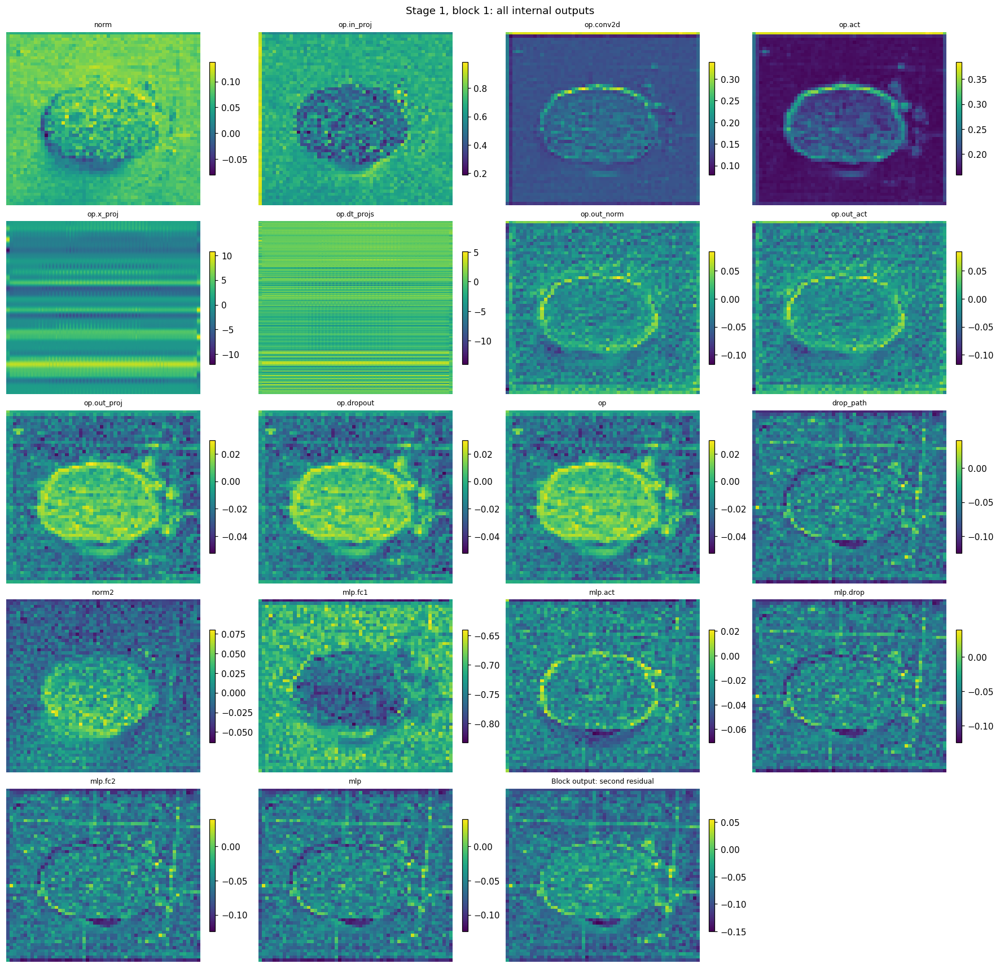

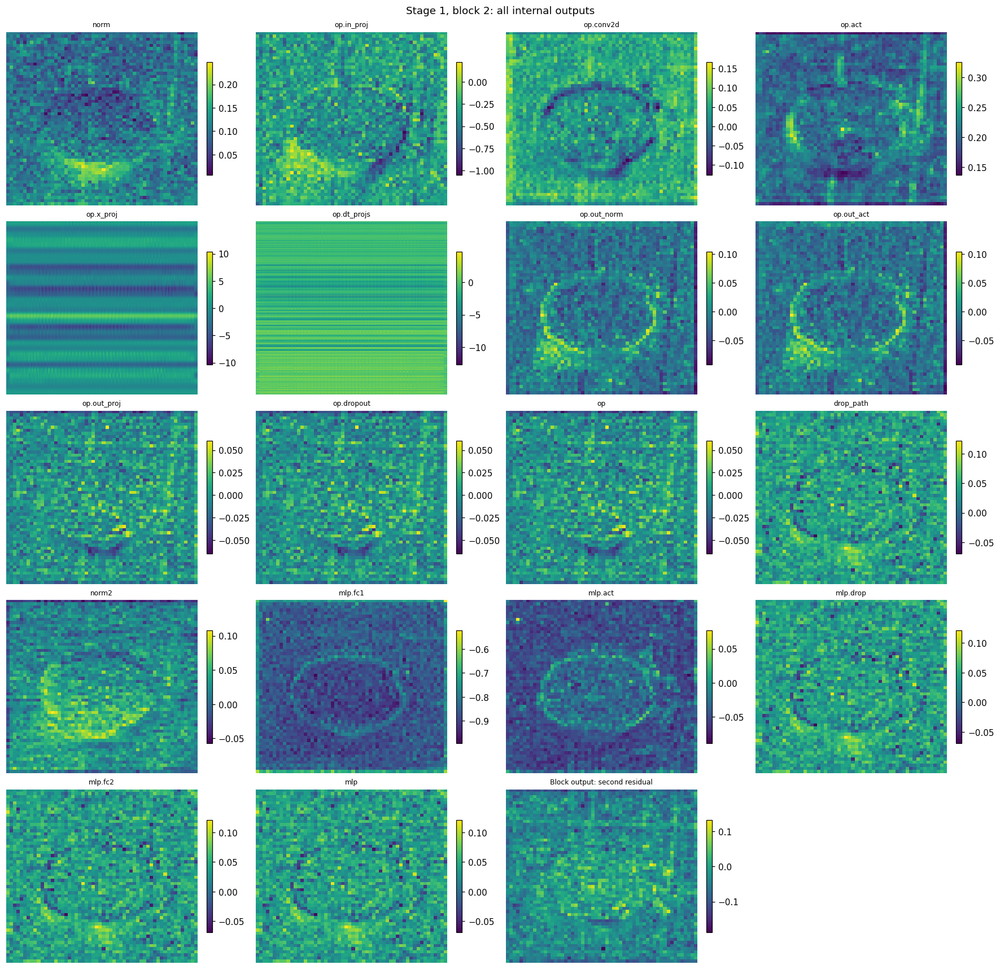

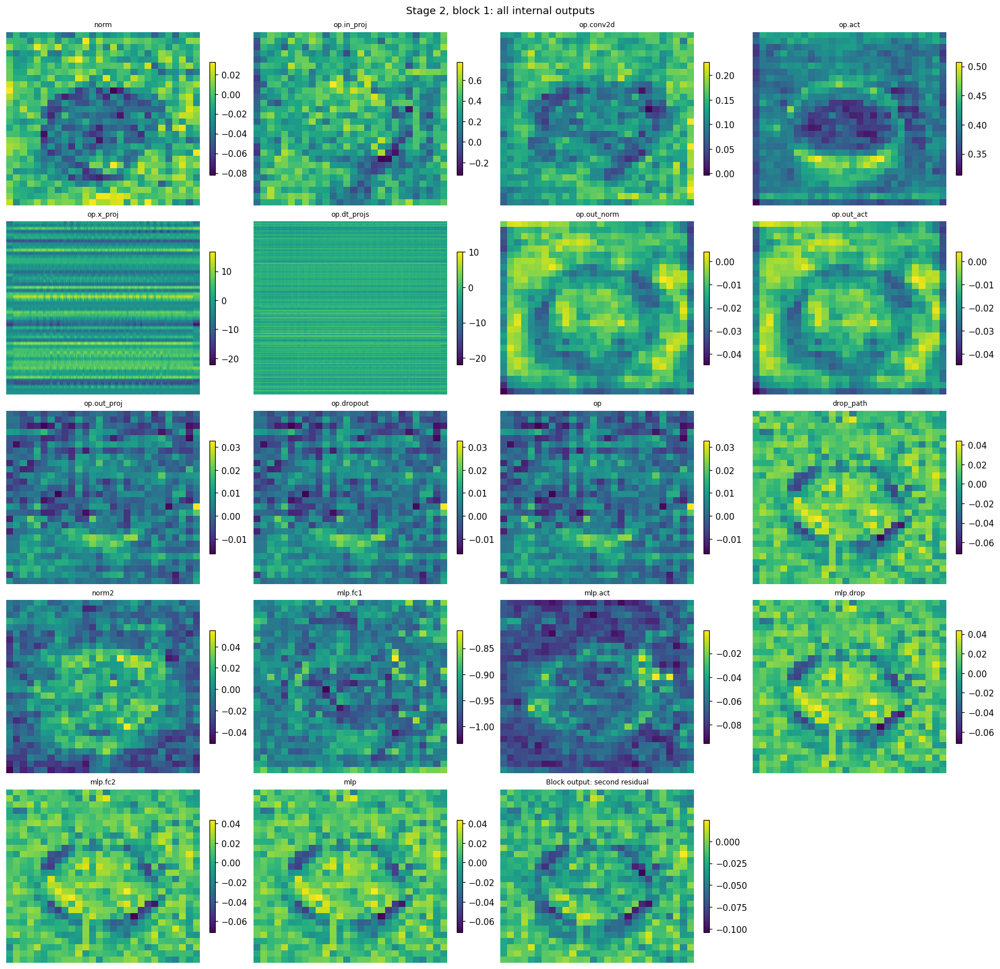

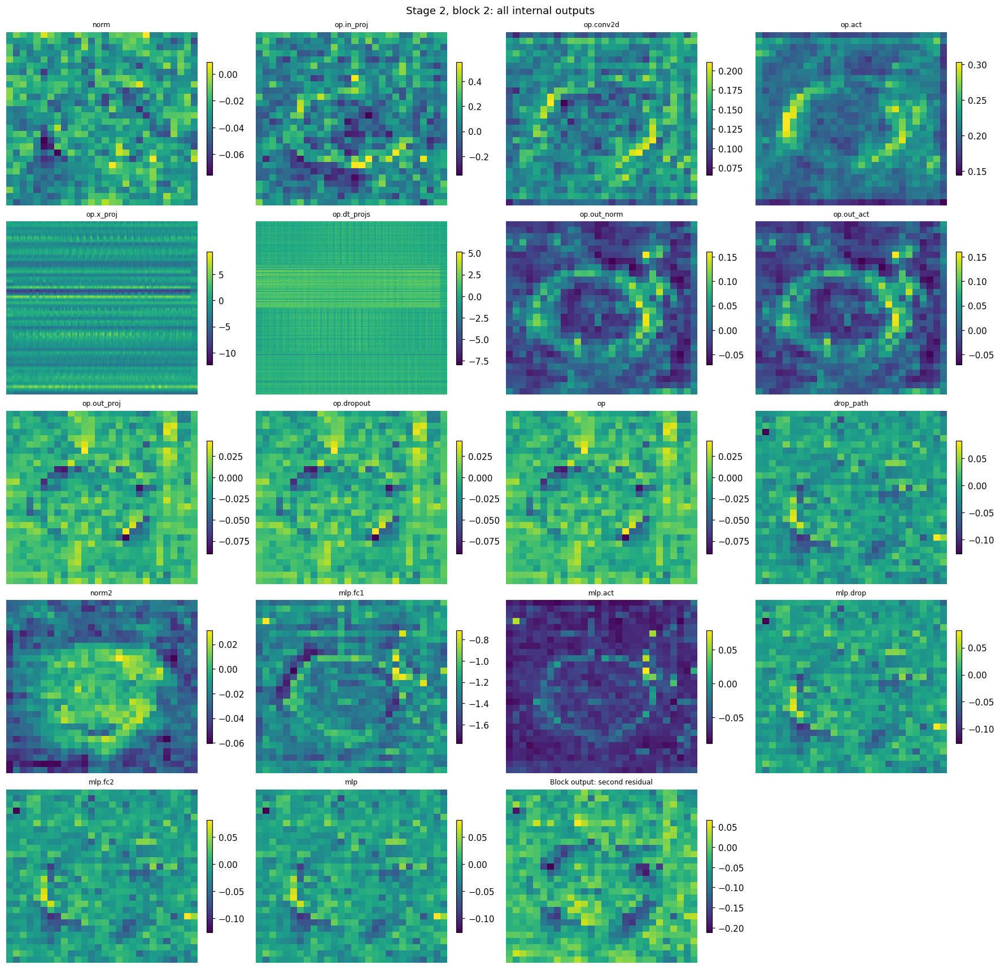

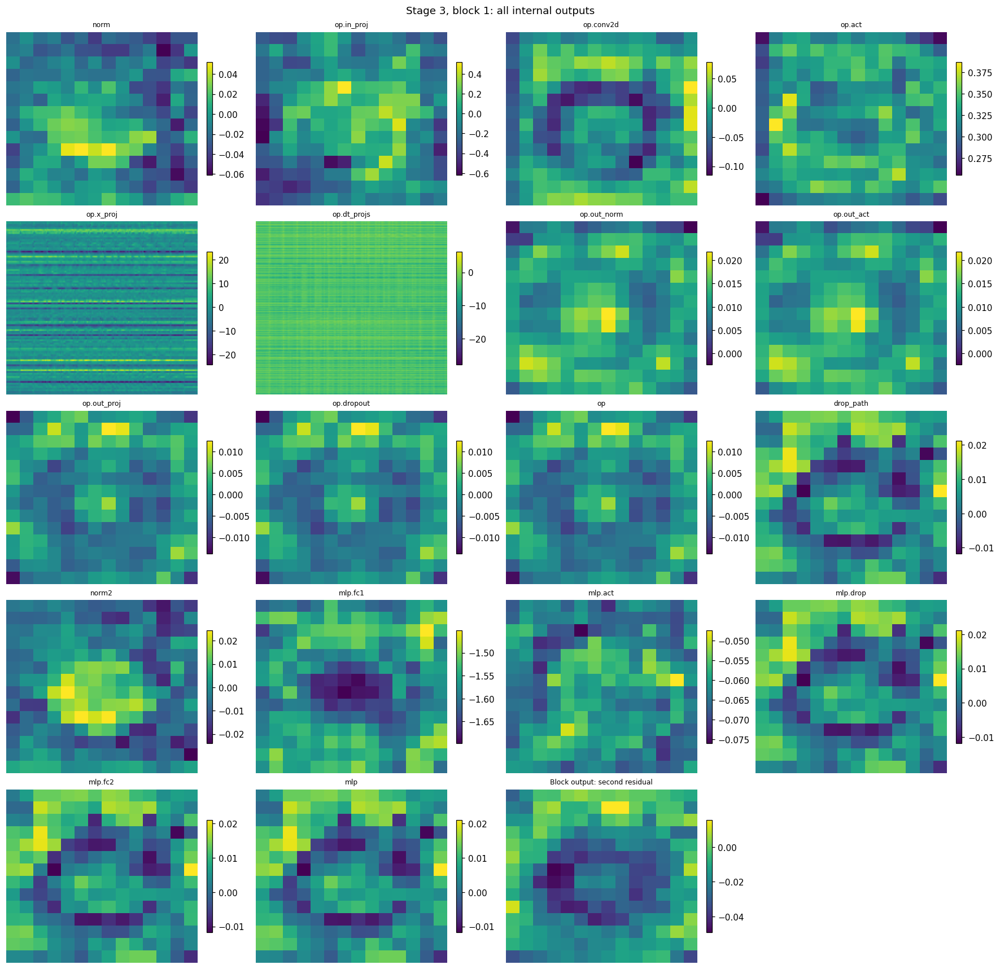

...

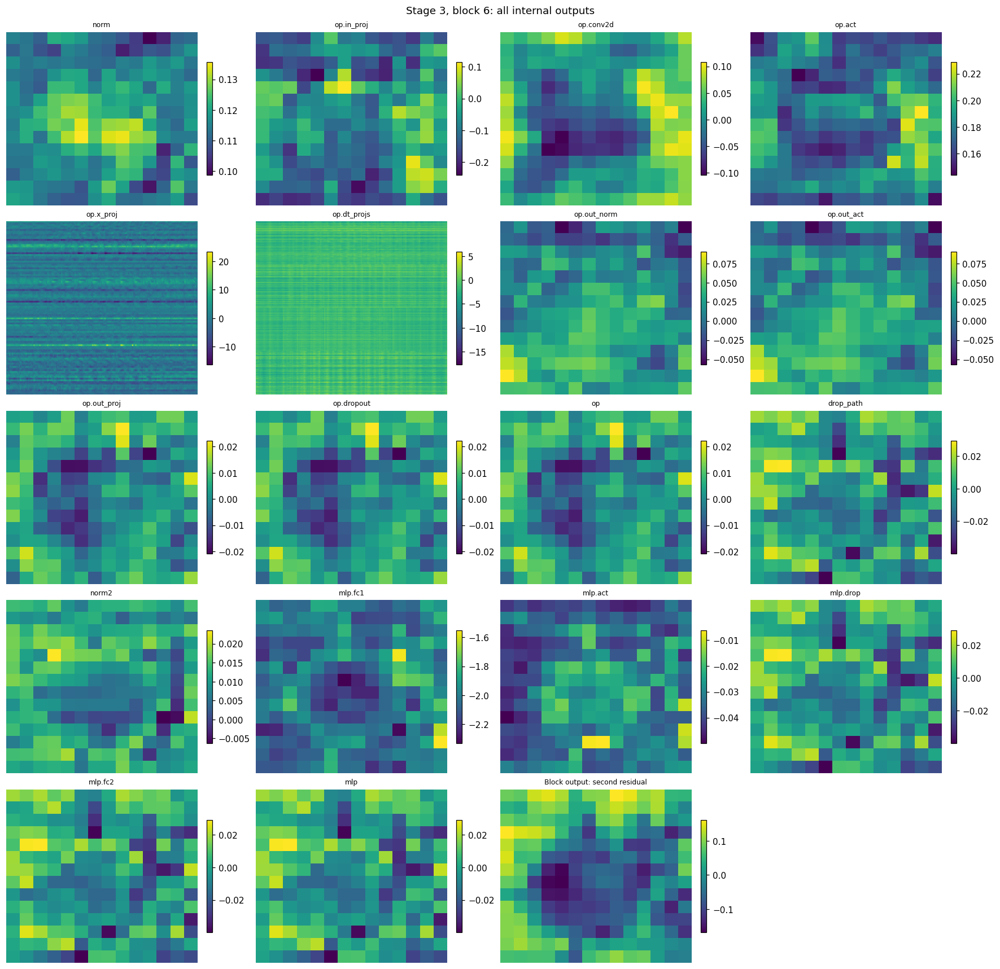

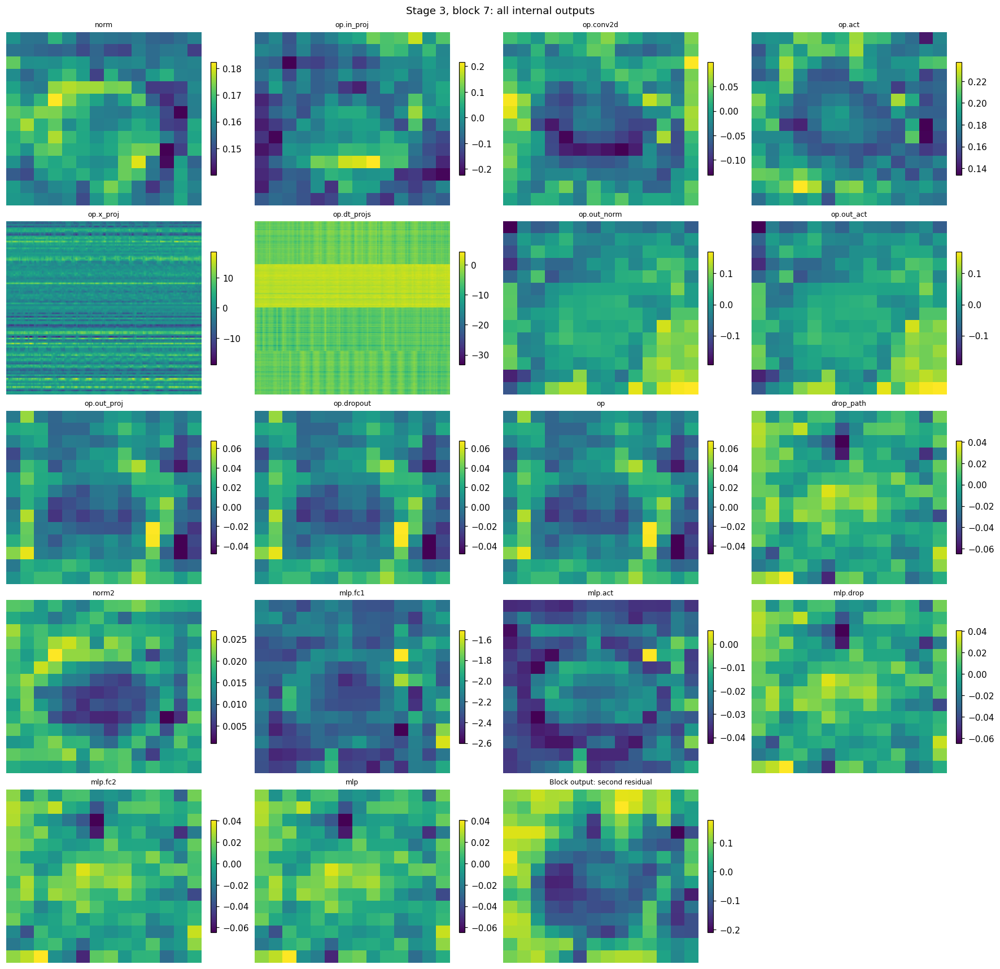

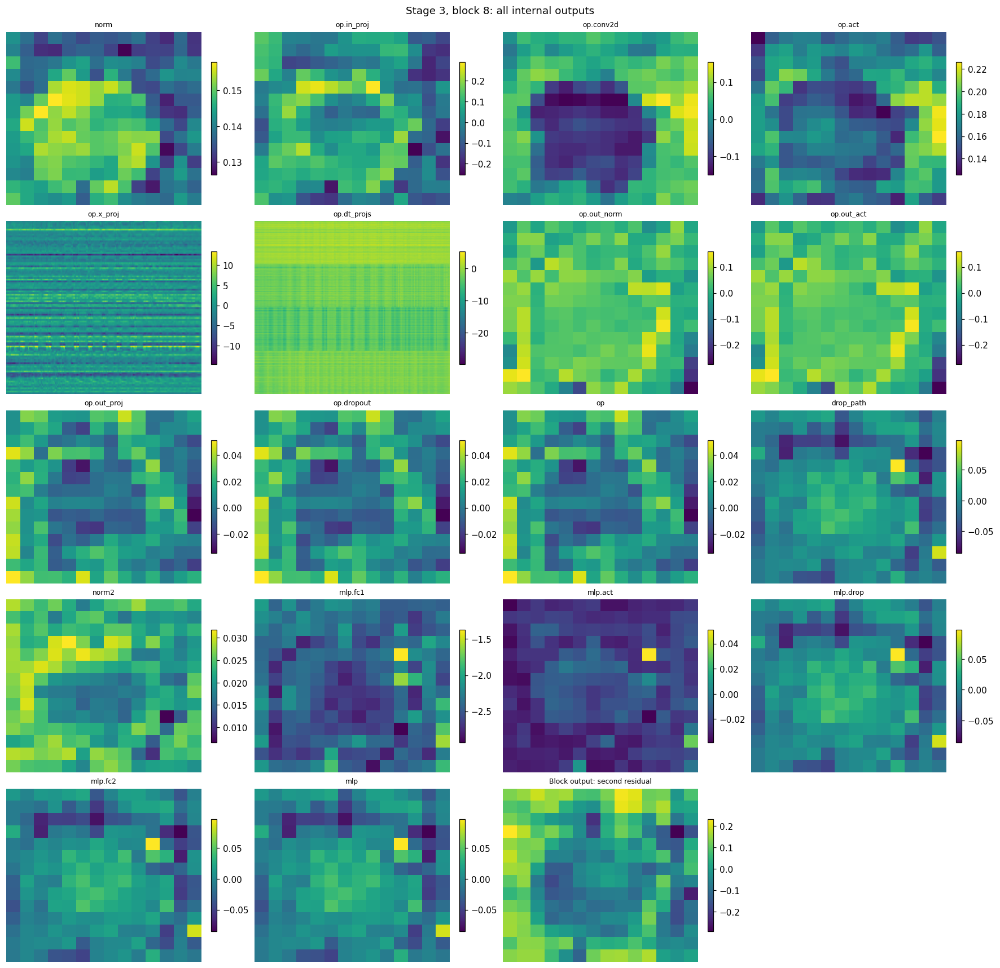

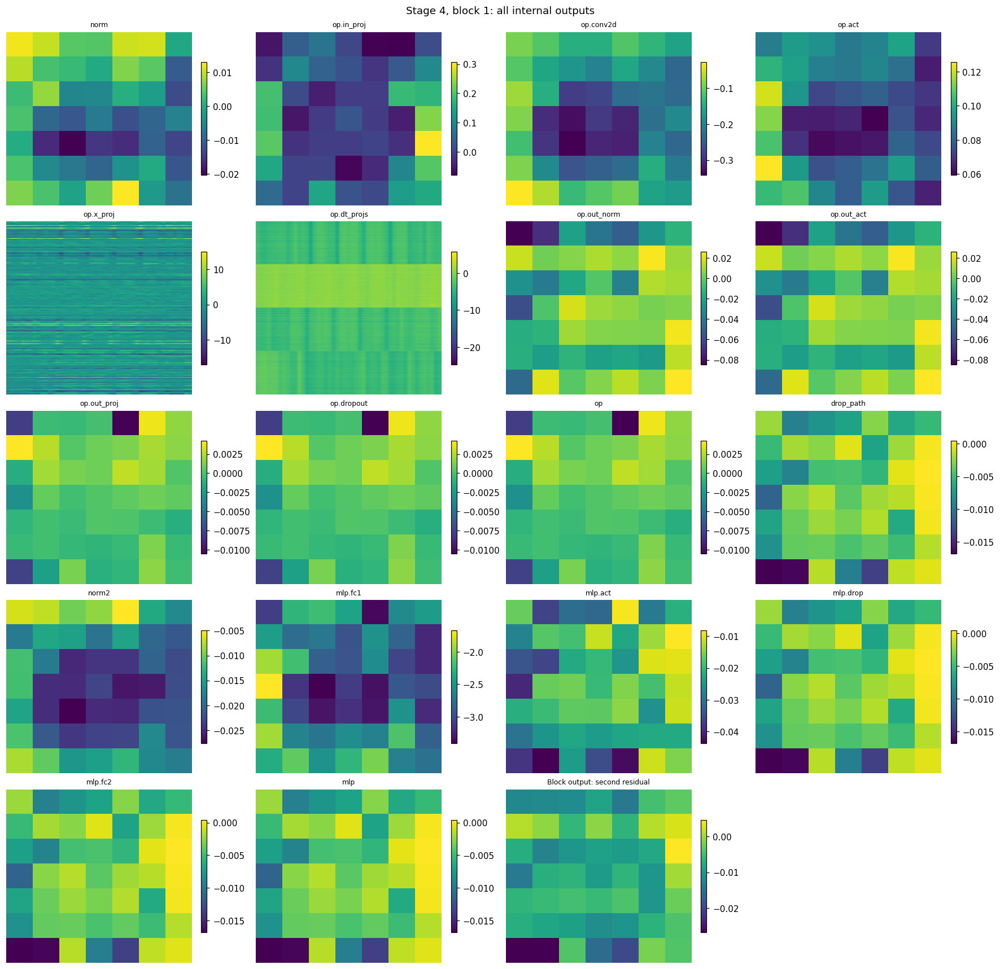

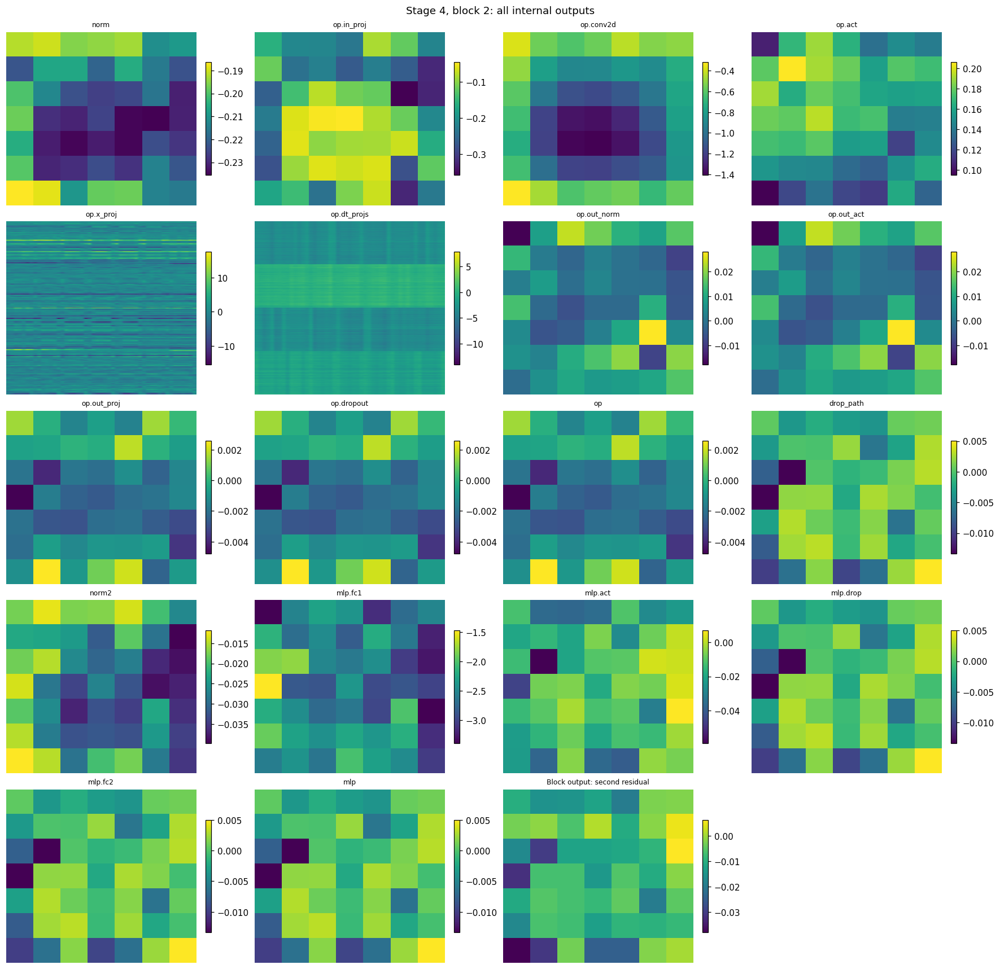

In [27]:
for stage_i,layer in enumerate(model.backbone.layers):
    for block_i,block in enumerate(layer.blocks):
        prefix=f'layers.{stage_i}.blocks.{block_i}'
        items=[(k.removeprefix(prefix+'.'),v) for k,v in trace.items()
               if k.startswith(prefix+'.')]
        items.append(('Block output: second residual',trace[prefix]))
        trace_gallery(items,f'Stage {stage_i+1}, block {block_i+1}: all internal outputs')

### Both residual additions for every block

A dedicated inference pass captures the block input, SS2D branch, MLP branch and output. It checks the exact equations first = input + SS2D and output = first + MLP. Adding spatial channel means is equivalent to averaging after addition. These feature residuals differ from the earlier three-channel RGB correction.

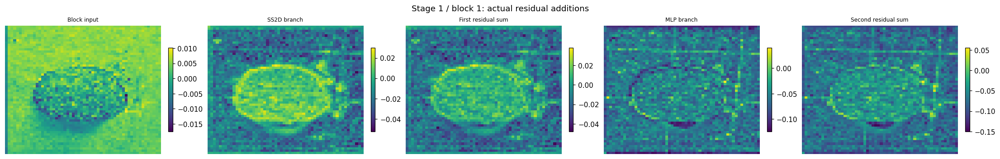

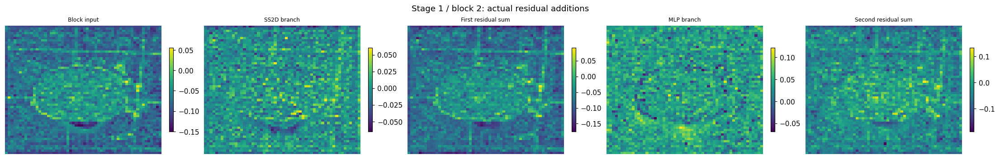

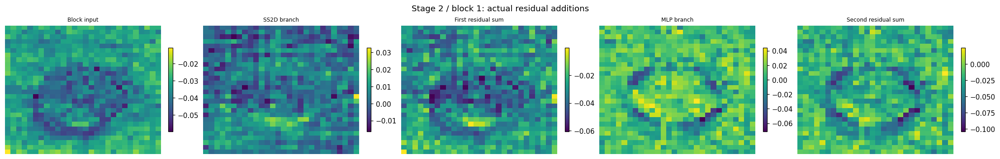

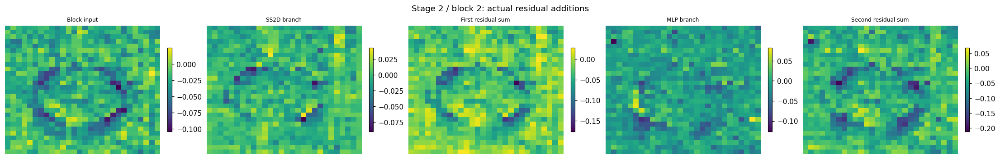

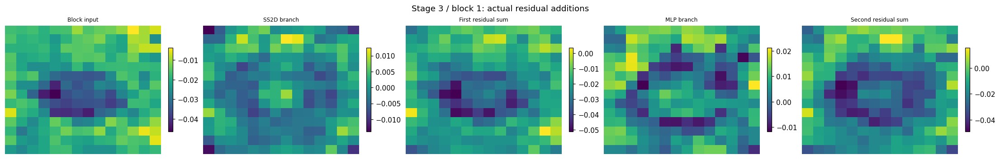

...

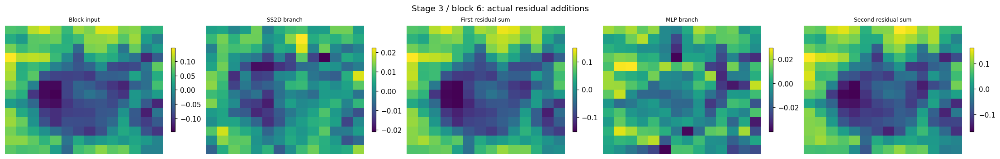

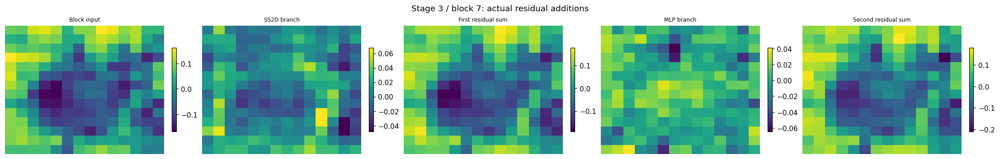

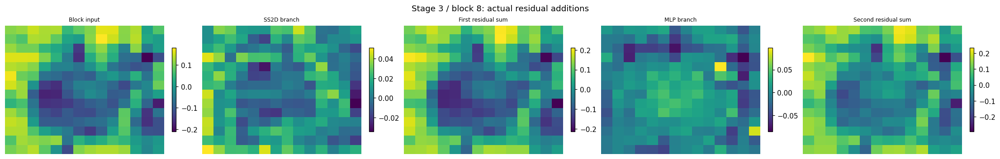

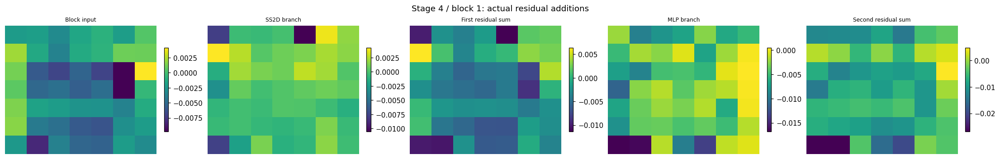

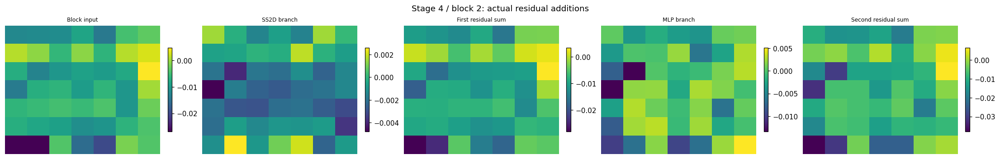

In [28]:
residuals={}; residual_handles=[]
def pre_residual(key):
    def hook(module,args): residuals[key]={'input':args[0].detach().clone()}
    return hook
def res_part(key,part):
    def hook(module,args,out): residuals[key][part]=out.detach().clone()
    return hook
for si,layer in enumerate(model.backbone.layers):
    for bi,block in enumerate(layer.blocks):
        key=f'Stage {si+1} / block {bi+1}'
        residual_handles.extend([block.register_forward_pre_hook(pre_residual(key)),
            block.op.register_forward_hook(res_part(key,'SS2D')),
            block.mlp.register_forward_hook(res_part(key,'MLP')),
            block.register_forward_hook(res_part(key,'output'))])
try:
    with torch.no_grad(): repeated_embedding=model.backbone(normalized)
finally:
    for h in residual_handles: h.remove()
torch.testing.assert_close(repeated_embedding,embedding)
for key,d in residuals.items():
    first=d['input']+d['SS2D']; second=first+d['MLP']
    torch.testing.assert_close(second,d['output'])
    trace_gallery([(n,t[0].float().mean(0).cpu().numpy()) for n,t in
        [('Block input',d['input']),('SS2D branch',d['SS2D']),('First residual sum',first),
         ('MLP branch',d['MLP']),('Second residual sum',second)]],
        key+': actual residual additions',cols=5)
residuals.clear()

## 14. Stage outputs and downsampling

Each stage image below is captured **before** its downsampler. Following stages 1–3, downsampling v3 applies an overlapping 3×3 stride-2 convolution and normalization. It halves spatial resolution and doubles channels. Stage 4 uses identity downsampling.

The pre-downsample grids are 96×56×56, 192×28×28, 384×14×14 and 768×7×7. Deeper grids combine larger contextual regions at lower resolution; their values no longer represent RGB colour.

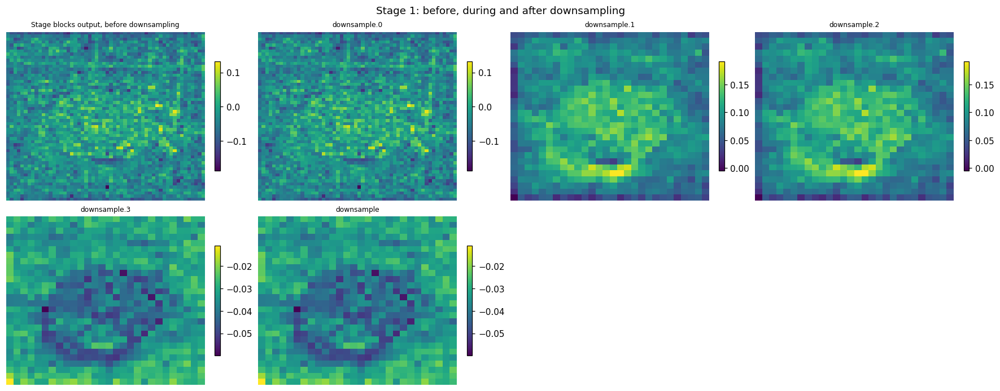

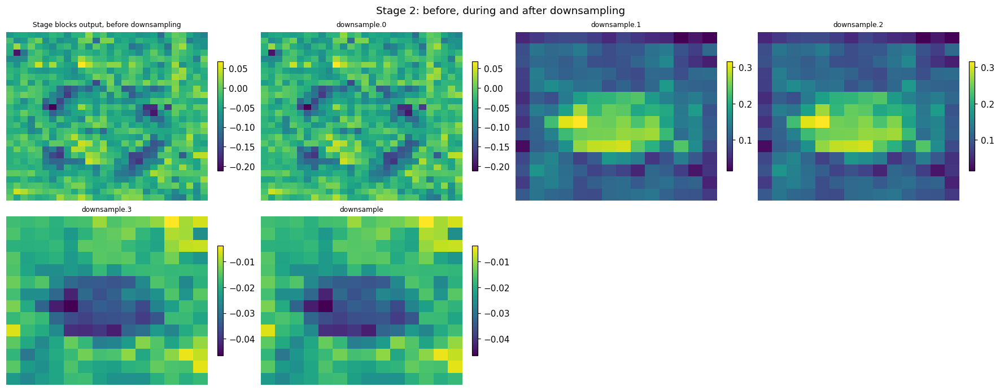

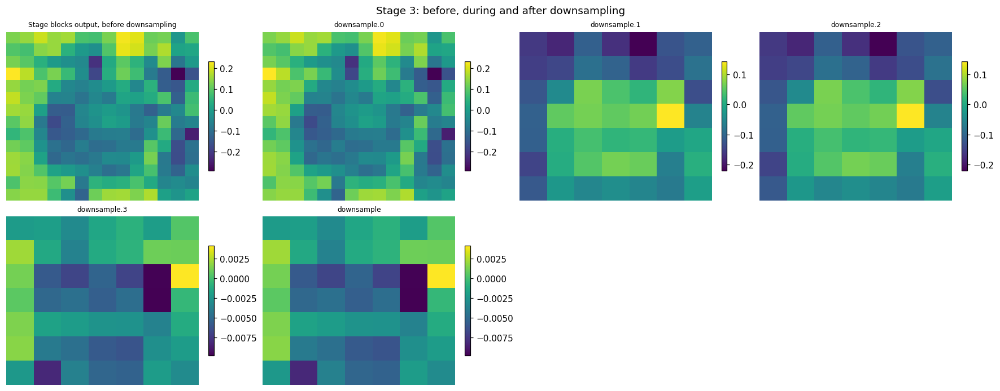

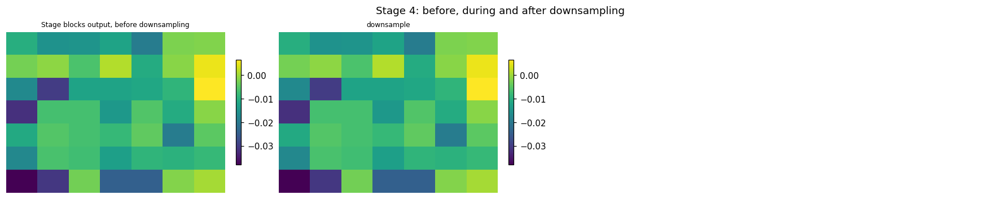

,Module,Shape,Min,Max,Mean
8,patch_embed,"(1, 96, 56, 56)",-2.259665,2.538059,0.002370
51,layers.0.blocks,"(1, 96, 56, 56)",-2.753664,2.507099,-0.030296
56,layers.0.downsample,"(1, 192, 28, 28)",-5.369580,3.171841,-0.034936
100,layers.1.blocks,"(1, 192, 28, 28)",-8.417687,4.301459,-0.038114
105,layers.1.downsample,"(1, 384, 14, 14)",-4.211129,5.308894,-0.021283
275,layers.2.blocks,"(1, 384, 14, 14)",-8.947142,13.533442,0.012523
280,layers.2.downsample,"(1, 768, 7, 7)",-8.069188,6.231332,-0.002862
324,layers.3.blocks,"(1, 768, 7, 7)",-36.805416,32.441212,-0.010387
325,layers.3.downsample,"(1, 768, 7, 7)",-36.805416,32.441212,-0.010387


In [29]:
for si in range(4):
    prefix=f'layers.{si}'
    items=[('Stage blocks output, before downsampling',trace[prefix+'.blocks'])]
    items.extend((k.removeprefix(prefix+'.'),v) for k,v in trace.items()
                 if k.startswith(prefix+'.downsample'))
    trace_gallery(items,f'Stage {si+1}: before, during and after downsampling')
stage_names=[f'layers.{i}.blocks' for i in range(4)]
display(trace_table.loc[trace_table.Module.isin(
    stage_names+['patch_embed',*[f'layers.{i}.downsample' for i in range(4)]])])

## 15. Final normalization, global average pooling and embedding

The last grid is 768×7×7. Final LayerNorm normalizes the grid, global average pooling reduces each channel's 49 positions to one number and flattening gives a 768-value feature vector. The original ImageNet 1,000-class head has been replaced with identity; the custom ordinal head makes the intensity decision.

After pooling there is no spatial image to reconstruct. The vector is displayed as a numeric strip.

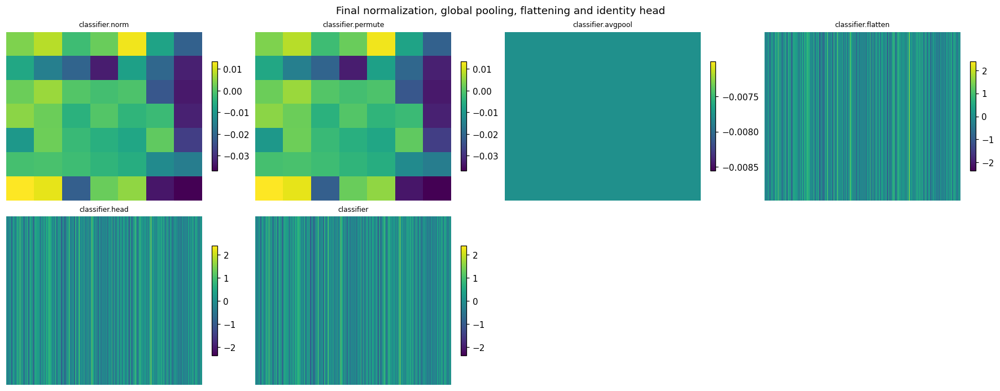

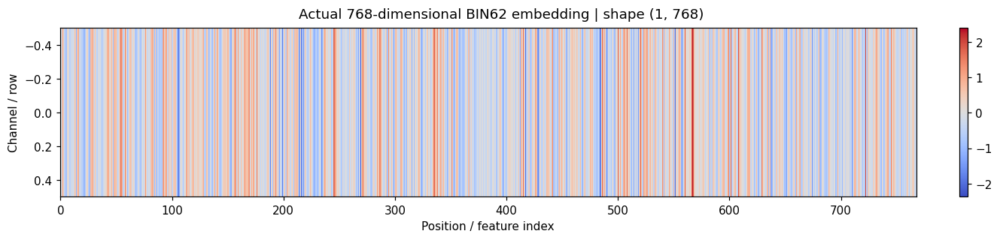

In [30]:
trace_gallery([(k,v) for k,v in trace.items() if k.startswith('classifier')],
    'Final normalization, global pooling, flattening and identity head')
feature_panel(embedding,'Actual 768-dimensional BIN62 embedding')

## 16. Ordinal head and actual intensity prediction

A learned bias-free linear layer gives scalar score s. The ordered thresholds are:

- t0 = first
- t1 = first + softplus(raw_gap) + 0.0001

Thus t1 > t0. Logits are [s−t0, s−t1]. Their sigmoids are q0 = P(y>Low) and q1 = P(y>Medium), with q0 ≥ q1. The final probabilities are:

- P(Low) = 1−q0
- P(Medium) = q0−q1
- P(High) = q1

The class with maximum probability is selected, as in the training notebook. This is not a three-logit softmax or a count of threshold crossings.

During training, cumulative binary-cross-entropy targets were Low [0,0], Medium [1,0], High [1,1]. Here no loss minimization or weight update occurs. All numbers below are computed from BIN62 and the saved trained weights.

,Threshold,Value,s - threshold,Cumulative probability
0,t0: above Low,-0.992236,13.490764,0.999999
1,t1: above Medium,2.915690,9.582838,0.999931


Learned scalar score: 12.498527526855469


,Intensity,Probability
0,Low,0.000001
1,Medium,0.000067
2,High,0.999931


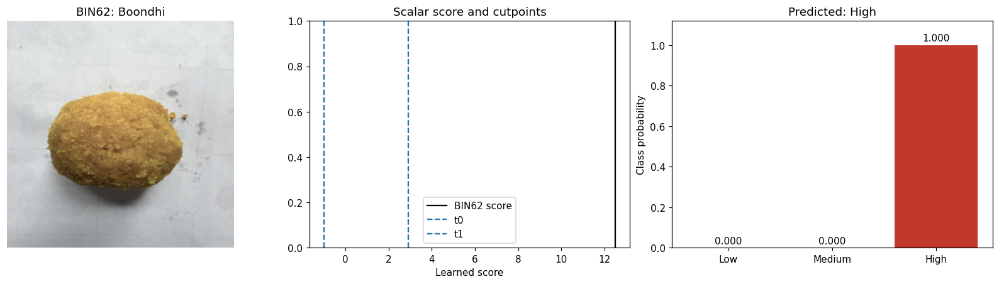

Recorded: High; predicted: High; probability: 0.9999
BIN62 belongs to training: this is a walkthrough, not a held-out evaluation.


In [31]:
with torch.no_grad():
    score=model.head.score(embedding)[0,0]
    thresholds=torch.stack([model.head.first,model.head.first+F.softplus(model.head.raw_gap)+1e-4])
    cumulative=logits.sigmoid()
    direct_logits=model(x)
    torch.testing.assert_close(logits,direct_logits,rtol=1e-5,atol=1e-6)
    assert bool(thresholds[1]>thresholds[0])
    assert bool((probabilities>=0).all())
    torch.testing.assert_close(probabilities.sum(1),torch.ones(1,device=DEVICE))
result=probabilities[0].cpu().numpy(); predicted=int(result.argmax())
display(pd.DataFrame({'Threshold':['t0: above Low','t1: above Medium'],
    'Value':thresholds.cpu().numpy(),'s - threshold':logits[0].cpu().numpy(),
    'Cumulative probability':cumulative[0].cpu().numpy()}))
print('Learned scalar score:',float(score))
display(pd.DataFrame({'Intensity':LABELS,'Probability':result}))
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].imshow(resized); axes[0].set_title('BIN62: Boondhi'); axes[0].axis('off')
axes[1].axvline(float(score),color='black',label='BIN62 score')
for i,t in enumerate(thresholds):
    axes[1].axvline(float(t),linestyle='--',label=f't{i}')
axes[1].set(title='Scalar score and cutpoints',xlabel='Learned score'); axes[1].legend()
axes[2].bar(LABELS,result,color=['#2980b9','#e6a700','#c0392b'])
axes[2].set(title=f'Predicted: {LABELS[predicted]}',ylabel='Class probability',ylim=(0,1.12))
for i,p in enumerate(result): axes[2].text(i,float(p)+.02,f'{p:.3f}',ha='center')
plt.show()
print(f"Recorded: {record.colouring_intensity}; predicted: {LABELS[predicted]}; probability: {result[predicted]:.4f}")
print('BIN62 belongs to training: this is a walkthrough, not a held-out evaluation.')

## 17. What happened to BIN62?

1. The JPEG became an oriented, resized float RGB tensor, retaining its whole background.
2. RGB, HSV and Lab supplied three numeric descriptions of the same pixels.
3. Learned projections and image-dependent gates combined them. A bounded learned residual adjusted RGB.
4. ImageNet normalization prepared the tensor for the fine-tuned backbone.
5. Patch convolutions built local features. Fourteen VSS blocks mixed local neighbourhoods with long-range context through four selective scans, residuals and MLPs.
6. Three downsamplers reduced the grids and expanded channels. Final normalization and average pooling yielded 768 features.
7. A scalar score and two ordered cutpoints produced the intensity probabilities above.

Early photographs show the food. Channel panels show colour encodings. Later maps show learned numeric feature responses and selective state-space behaviour. They are not segmentation masks or causal explanations; the colour gates show branch weighting. Image category predictions do not identify a dye, quantify its concentration or establish food safety.

**Sources within this project:** model definitions copied from 02_training_evaluation.ipynb; settings, preprocessing, selected epoch, class mapping and source hash read from outputs/best_csmon.pt; identity and split read from outputs/split_manifest.csv. Detailed backbone operations use the pinned cached official VMamba source. The code checks explicit intermediate reconstruction against direct full-model inference.

Save this notebook after Run All to retain all inline image outputs. There are no separate image files to manage.